# Project Overview
# Boston 311 Demand Forecasting for 2025
Objective: Forecast monthly service request volumes for four City of Boston departments in 2025 using historical Boston 311 data from 2023 and 2024.

This analysis is the first stage of our Hackathon which focuses on developing a dynamic staffing plan for Boston's city service teams. Accurate demand estimates are important because departments need to anticipate workload fluctuations and adjust staffing while balancing operating costs and service performance.

The four departments analyzed are Public Works (PWDx), Transportation (BTDT), Parks & Recreation (PARK), and Inspectional Services (ISD).

The forecasting process includes data preparation, exploratory analysis, comparison of forecasting methods, 2025 demand projections, and sensitivity analysis. The resulting forecasts will serve as inputs for the team's staffing optimization model.

In [7]:
#Importing Python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

file_2023 = DATA_DIR / "lagan_311_open_data_2023_rvsd3.csv"
file_2024 = DATA_DIR / "lagan_311_open_data_2024_rvsd3.csv"

assert file_2023.exists(), f"File not found: {file_2023}"
assert file_2024.exists(), f"File not found: {file_2024}"

df_2023 = pd.read_csv(file_2023, low_memory=False)
df_2024 = pd.read_csv(file_2024, low_memory=False)

print("2023:", df_2023.shape)
print("2024:", df_2024.shape)
display(df_2024.head())

2023: (307791, 30)
2024: (306756, 30)


,case_enquiry_id,open_dt,sla_target_dt,closed_dt,on_time,case_status,closure_reason,case_title,subject,reason,...,neighborhood,neighborhood_services_district,ward,precinct,location_street_name,location_zipcode,latitude,longitude,geom_4326,source
0,101005236041,2024-01-04 10:43:17.097,NaN,2024-01-04 11:23:49.81,ONTIME,Closed,Case Closed. Closed date : Thu Jan 04 11:23:49...,Needle Pickup,Mayor's 24 Hour Hotline,Needle Program,...,Fenway / Kenmore / Audubon Circle / Longwood,14.0,5,0502A,INTERSECTION Jersey St &amp; Peterborough St,NaN,42.343691,-71.097398,0101000020E6100000FD0D6DC53BC651C0FC30C60DFE2B...,Citizens Connect App
1,101005236307,2024-01-04 12:36:07.337,2024-01-05 12:36:09,2024-01-04 14:55:49.667,ONTIME,Closed,Case Closed. Closed date : Thu Jan 04 14:55:49...,Requests for Street Cleaning,Public Works Department,Street Cleaning,...,Fenway / Kenmore / Audubon Circle / Longwood,14.0,Ward 5,0502A,115 Jersey St,2215.0,42.342650,-71.097110,0101000020E6100000C8E0DD0C37C651C057A987F4DB2B...,Employee Generated
2,101005240045,2024-01-08 07:24:00,2024-01-10 07:24:23,2024-01-08 13:50:08.237,ONTIME,Closed,Case Closed. Closed date : Mon Jan 08 13:50:08...,Unshoveled Sidewalk,Public Works Department,Code Enforcement,...,Fenway / Kenmore / Audubon Circle / Longwood,14.0,5,0502A,INTERSECTION Kilmarnock St &amp; Boylston St,NaN,42.343969,-71.100013,0101000020E6100000229BFD9C66C651C0EAB5342A072C...,Employee Generated
3,101005244677,2024-01-10 20:57:00,2025-12-30 20:57:18,2024-02-01 10:23:56.19,ONTIME,Closed,Case Closed. Closed date : Thu Feb 01 10:23:56...,Working Beyond Hours,Inspectional Services,Building,...,Boston,14.0,05,0502A,60 Kilmarnock St,2215.0,42.342751,-71.099143,0101000020E6100000A124755A58C651C09E0BE041DF2B...,Constituent Call
4,101005245980,2024-01-11 18:37:50.243,2024-01-16 08:30:00,2024-01-11 18:38:03.61,ONTIME,Closed,Case Closed. Closed date : 2024-01-11 18:38:03...,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,...,Boston,14.0,05,0502A,1341 Boylston St,2215.0,42.344245,-71.099854,0101000020E61000009DB0280064C651C033FB0B35102C...,Employee Generated


In [9]:
# Convert date columns to datetime
for df in [df_2023, df_2024]:
    df["open_dt"] = pd.to_datetime(
        df["open_dt"],
        format="mixed",
        errors="coerce"
    )

# Verify the conversion worked
print("2023:", df_2023["open_dt"].dtype)
print("2024:", df_2024["open_dt"].dtype)

2023: datetime64[us]
2024: datetime64[us]


In [10]:
#filtering the 4 departments

# Departments required by the hackathon
departments = ["PWDx", "BTDT", "PARK", "ISD"]

# Combine both years
df = pd.concat([df_2023, df_2024], ignore_index=True)

# Keep only the four departments
df = df[df["department"].isin(departments)].copy()

# Extract year and month
df["year"] = df["open_dt"].dt.year
df["month"] = df["open_dt"].dt.month

print("Filtered dataset:", df.shape)
display(df["department"].value_counts())

Filtered dataset: (558663, 32)


department
PWDx    328878
BTDT    156761
ISD      36747
PARK     36277
Name: count, dtype: int64

The analysis uses publicly available Boston 311 service request records from 2023 and 2024. The datasets contain 307,791 and 306,756 records, respectively.

The datasets were loaded using Pandas, and the open_dt column was converted into a consistent datetime format to handle variations in timestamp precision. Both years were then combined into a single dataset, and records were filtered to include only the four departments specified in the assignment.

The filtered dataset contains 558,663 requests across the two years. Year and month variables were extracted from each request's opening date to support monthly demand analysis.

Each request is counted in the month it was opened, rather than the month it was closed, because the objective is to estimate incoming service demand.

Calculating Monthly Demand

In [11]:
# Count service requests by year, month, and department
monthly_demand = (
    df.groupby(["year", "month", "department"])
    .size()
    .reset_index(name="requests")
    .sort_values(["department", "year", "month"])
)

print("Total department-month combinations:", len(monthly_demand))
display(monthly_demand.head(15))

Total department-month combinations: 96


,year,month,department,requests
0,2023,1,BTDT,5692
4,2023,2,BTDT,5316
8,2023,3,BTDT,6889
12,2023,4,BTDT,6143
16,2023,5,BTDT,6737
20,2023,6,BTDT,6682
24,2023,7,BTDT,5517
28,2023,8,BTDT,6473
32,2023,9,BTDT,7190
36,2023,10,BTDT,7018


Creating seasonal demand graphs

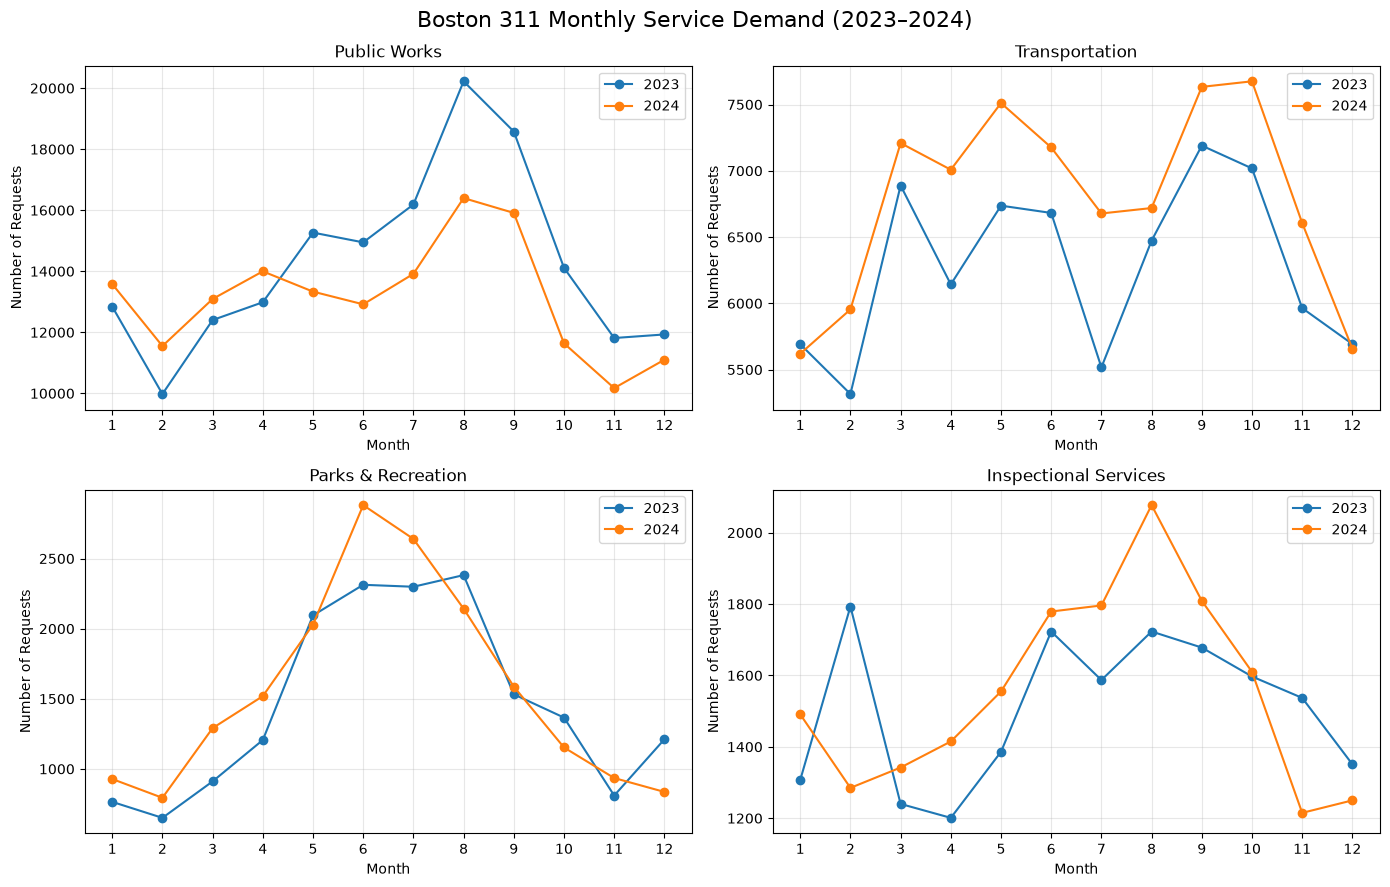

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

department_names = {
    "PWDx": "Public Works",
    "BTDT": "Transportation",
    "PARK": "Parks & Recreation",
    "ISD": "Inspectional Services"
}

for ax, (code, name) in zip(axes.flatten(), department_names.items()):

    subset = monthly_demand[
        monthly_demand["department"] == code
    ]

    for year in [2023, 2024]:
        year_data = subset[subset["year"] == year]

        ax.plot(
            year_data["month"],
            year_data["requests"],
            marker="o",
            label=str(year)
        )

    ax.set_title(name)
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Requests")
    ax.set_xticks(range(1, 13))
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Boston 311 Monthly Service Demand (2023–2024)",
    fontsize=16
)
plt.tight_layout()
plt.show()

Historical request volumes reveal different seasonal patterns across the four departments.

Public Works: Demand increases during warmer months, peaking in August in both years. However, total request volume decreased by approximately 8% from 2023 to 2024.

Transportation: Demand is comparatively stable throughout the year, with relatively high volumes during spring and early fall. Annual demand increased by approximately 8.1%.

Parks & Recreation: This department exhibits the strongest seasonal pattern. Demand rises substantially from winter to summer, reaching its peak around June and July, before declining during fall.

Inspectional Services: Requests show moderate seasonal fluctuations, with generally higher demand during summer. Annual demand increased slightly, by approximately 2.8%.

These patterns suggest that a constant monthly demand assumption would not adequately capture workload fluctuations. Therefore, the forecasting model should preserve department-specific seasonality.

# Building and Comparing Forecasting Models
Three forecasting methods were developed to estimate monthly request volumes in 2025.

Method 1 — Seasonal Naïve Forecast

The forecast for each month of 2025 equals the observed request volume for the corresponding month in 2024. This approach assumes that demand patterns repeat from the most recent year.

Method 2 — Two-Year Seasonal Average

The forecast for each month of 2025 is calculated as the average of the corresponding monthly request volumes from 2023 and 2024. This method preserves seasonal demand patterns while reducing the influence of fluctuations occurring in either individual year.

Method 3 — Trend-Adjusted Seasonal Forecast

The annual growth rate between 2023 and 2024 is calculated separately for each department and applied to its corresponding monthly 2024 volumes. This method incorporates recent growth or decline while preserving the monthly demand distribution observed in 2024.

All three approaches were compared to examine how different assumptions affect projected demand. Because only two historical years are available, the comparison is based on interpretability and planning plausibility rather than a comprehensive out-of-sample accuracy evaluation.

In [13]:
#Prepare the montly demand table
monthly_pivot = monthly_demand.pivot_table(
    index=["department", "month"],
    columns="year",
    values="requests"
).reset_index()

monthly_pivot.columns.name = None

monthly_pivot = monthly_pivot.rename(
    columns={2023: "requests_2023", 2024: "requests_2024"}
)

display(monthly_pivot.head(12))

,department,month,requests_2023,requests_2024
0,BTDT,1,5692.0,5620.0
1,BTDT,2,5316.0,5954.0
2,BTDT,3,6889.0,7209.0
3,BTDT,4,6143.0,7008.0
4,BTDT,5,6737.0,7511.0
5,BTDT,6,6682.0,7176.0
6,BTDT,7,5517.0,6678.0
7,BTDT,8,6473.0,6719.0
8,BTDT,9,7190.0,7633.0
9,BTDT,10,7018.0,7675.0


In [14]:
#Calculate the annual growth rates
annual_totals = (
    monthly_demand.groupby(["department", "year"])["requests"]
    .sum()
    .unstack()
)

annual_totals["growth_rate"] = (
    annual_totals[2024] / annual_totals[2023] - 1
)

display(annual_totals)

year,2023,2024,growth_rate
department,,,
BTDT,75314,81447,0.081432
ISD,18123,18624,0.027644
PARK,17541,18736,0.068126
PWDx,171268,157610,-0.079746


In [15]:
#Generate 3 candidate forecasts
forecast_comparison = monthly_pivot.copy()

# Method 1: Seasonal naive
forecast_comparison["seasonal_naive"] = (
    forecast_comparison["requests_2024"]
)

# Method 2: Two-year seasonal average
forecast_comparison["seasonal_average"] = (
    forecast_comparison[
        ["requests_2023", "requests_2024"]
    ].mean(axis=1)
)

# Method 3: Trend-adjusted seasonal forecast
growth_rates = annual_totals["growth_rate"].to_dict()

forecast_comparison["trend_adjusted"] = (
    forecast_comparison["requests_2024"]
    * forecast_comparison["department"].map(
        lambda d: 1 + growth_rates[d]
    )
)

display(forecast_comparison.head(12))

,department,month,requests_2023,requests_2024,seasonal_naive,seasonal_average,trend_adjusted
0,BTDT,1,5692.0,5620.0,5620.0,5656.0,6077.650105
1,BTDT,2,5316.0,5954.0,5954.0,5635.0,6438.848527
2,BTDT,3,6889.0,7209.0,7209.0,7049.0,7796.046193
3,BTDT,4,6143.0,7008.0,7008.0,6575.5,7578.678280
4,BTDT,5,6737.0,7511.0,7511.0,7124.0,8122.638779
5,BTDT,6,6682.0,7176.0,7176.0,6929.0,7760.358924
6,BTDT,7,5517.0,6678.0,6678.0,6097.5,7221.805587
7,BTDT,8,6473.0,6719.0,6719.0,6596.0,7266.144316
8,BTDT,9,7190.0,7633.0,7633.0,7411.5,8254.573532
9,BTDT,10,7018.0,7675.0,7675.0,7346.5,8299.993693


Comparing all 3 forecast methods visually

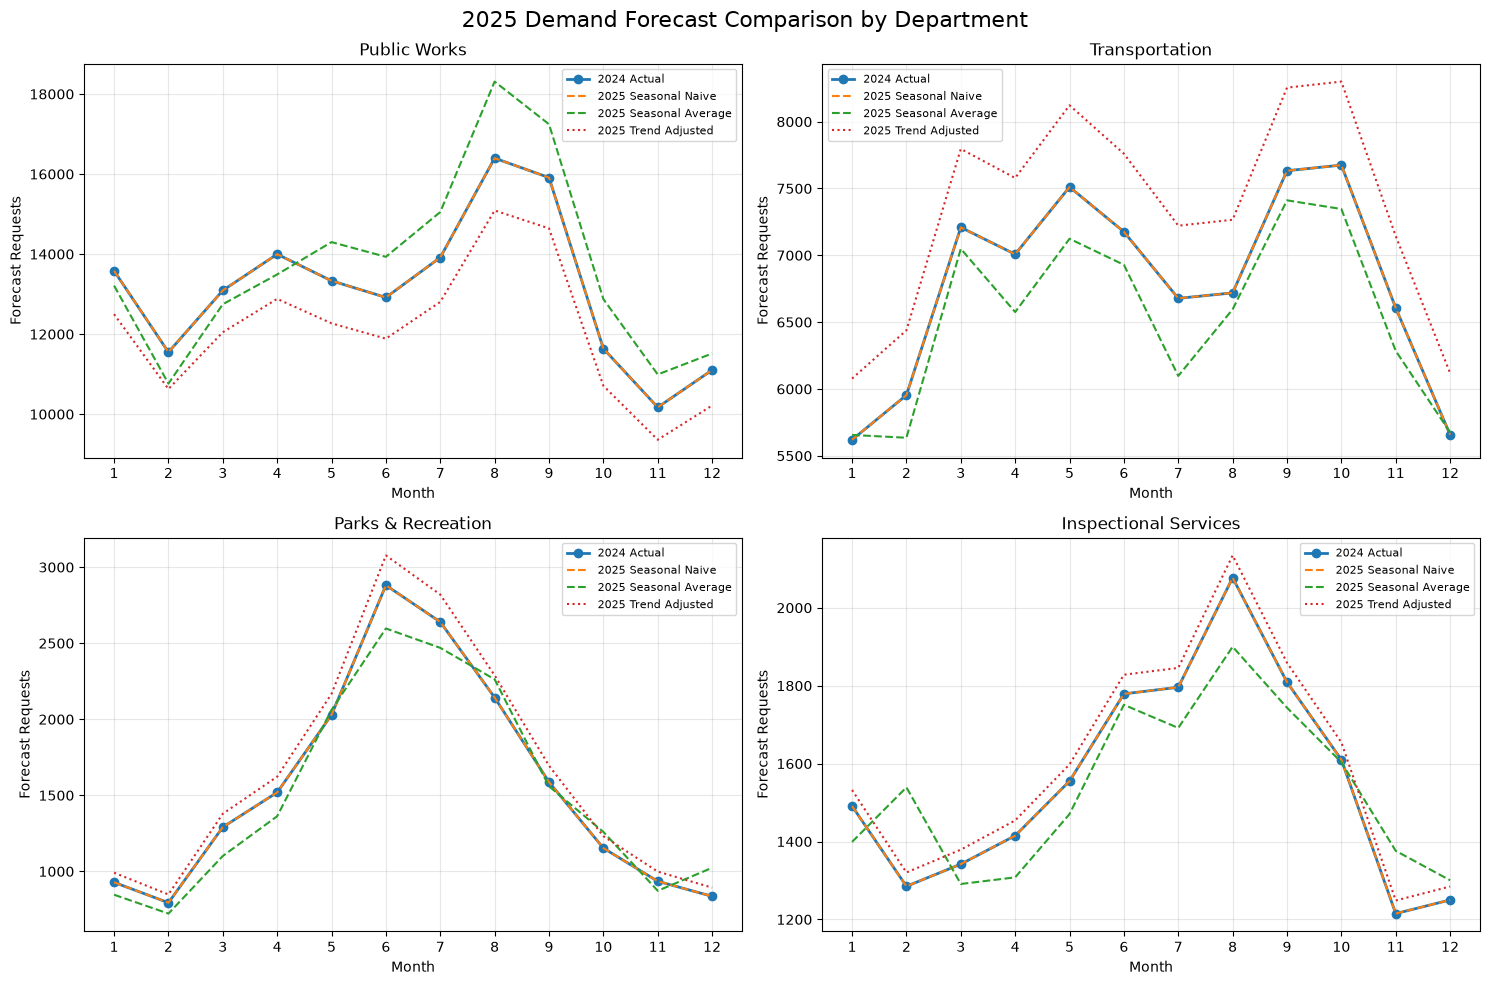

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (code, name) in zip(
    axes.flatten(), department_names.items()
):
    subset = forecast_comparison[
        forecast_comparison["department"] == code
    ].sort_values("month")

    ax.plot(
        subset["month"],
        subset["requests_2024"],
        label="2024 Actual",
        marker="o",
        linewidth=2
    )

    ax.plot(
        subset["month"],
        subset["seasonal_naive"],
        label="2025 Seasonal Naive",
        linestyle="--"
    )

    ax.plot(
        subset["month"],
        subset["seasonal_average"],
        label="2025 Seasonal Average",
        linestyle="--"
    )

    ax.plot(
        subset["month"],
        subset["trend_adjusted"],
        label="2025 Trend Adjusted",
        linestyle=":"
    )

    ax.set_title(name)
    ax.set_xlabel("Month")
    ax.set_ylabel("Forecast Requests")
    ax.set_xticks(range(1, 13))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle(
    "2025 Demand Forecast Comparison by Department",
    fontsize=16
)
plt.tight_layout()
plt.show()

The three forecasting approaches produce different estimates, particularly for departments experiencing significant changes between 2023 and 2024.

For example, Public Works experienced a decline of approximately 8%, causing the trend-adjusted method to project lower demand. Conversely, Transportation experienced approximately 8.1% growth, resulting in higher projections under the trend-adjusted method.

The two-year seasonal average was selected as the baseline forecasting method. This approach maintains the seasonal patterns observed in historical data while moderating the effect of recent year-over-year changes.

Because only two years of historical observations are available, extending one year's growth rate into 2025 could introduce unnecessary uncertainty.

The selected method is therefore a transparent and reasonably conservative planning assumption, although its predictive accuracy has not been independently established.

Exporting the final forecast for next steps

In [18]:
final_forecast = forecast_comparison[
    ["department", "month", "seasonal_average"]
].copy()

final_forecast["month"] = (
    "2025-" +
    final_forecast["month"].astype(str).str.zfill(2)
)

final_forecast = final_forecast.rename(
    columns={"seasonal_average": "forecast_requests"}
)

final_forecast["forecast_requests"] = np.floor(
    final_forecast["forecast_requests"] + 0.5
).astype(int)

final_forecast = final_forecast.sort_values(
    ["department", "month"]
).reset_index(drop=True)

assert len(final_forecast) == 48

display(final_forecast)

forecast_path = OUTPUT_DIR / "boston_311_2025_forecast.csv"

final_forecast.to_csv(
    forecast_path,
    index=False
)

print(f"Forecast saved to: {forecast_path}")

,department,month,forecast_requests
0,BTDT,2025-01,5656
1,BTDT,2025-02,5635
2,BTDT,2025-03,7049
3,BTDT,2025-04,6576
4,BTDT,2025-05,7124
5,BTDT,2025-06,6929
6,BTDT,2025-07,6098
7,BTDT,2025-08,6596
8,BTDT,2025-09,7412
9,BTDT,2025-10,7347


Forecast saved to: /Users/mihir/Desktop/Hackathon/data/output/boston_311_2025_forecast.csv


### Demand Sensitivity Scenarios

To evaluate uncertainty in projected service demand, two alternative scenarios were created alongside the baseline forecast:

Low-demand scenario: 20% fewer requests than forecast.

High-demand scenario: 20% more requests than forecast.

These scenarios represent hypothetical deviations from expected demand rather than statistical confidence intervals.

The sensitivity analysis allows the staffing optimization model to evaluate whether planned crew levels remain adequate when actual request volumes differ from expectations. It also supports comparisons of labor costs, potential backlogs, and service performance across alternative demand conditions.

In [19]:
sensitivity = final_forecast.copy()

sensitivity["low_demand"] = np.floor(
    sensitivity["forecast_requests"] * 0.8 + 0.5
).astype(int)

sensitivity["high_demand"] = np.floor(
    sensitivity["forecast_requests"] * 1.2 + 0.5
).astype(int)

display(sensitivity.head(12))

sensitivity.to_csv(
    "boston_311_demand_scenarios.csv",
    index=False
)

,department,month,forecast_requests,low_demand,high_demand
0,BTDT,2025-01,5656,4525,6787
1,BTDT,2025-02,5635,4508,6762
2,BTDT,2025-03,7049,5639,8459
3,BTDT,2025-04,6576,5261,7891
4,BTDT,2025-05,7124,5699,8549
5,BTDT,2025-06,6929,5543,8315
6,BTDT,2025-07,6098,4878,7318
7,BTDT,2025-08,6596,5277,7915
8,BTDT,2025-09,7412,5930,8894
9,BTDT,2025-10,7347,5878,8816


2025 forecast alone

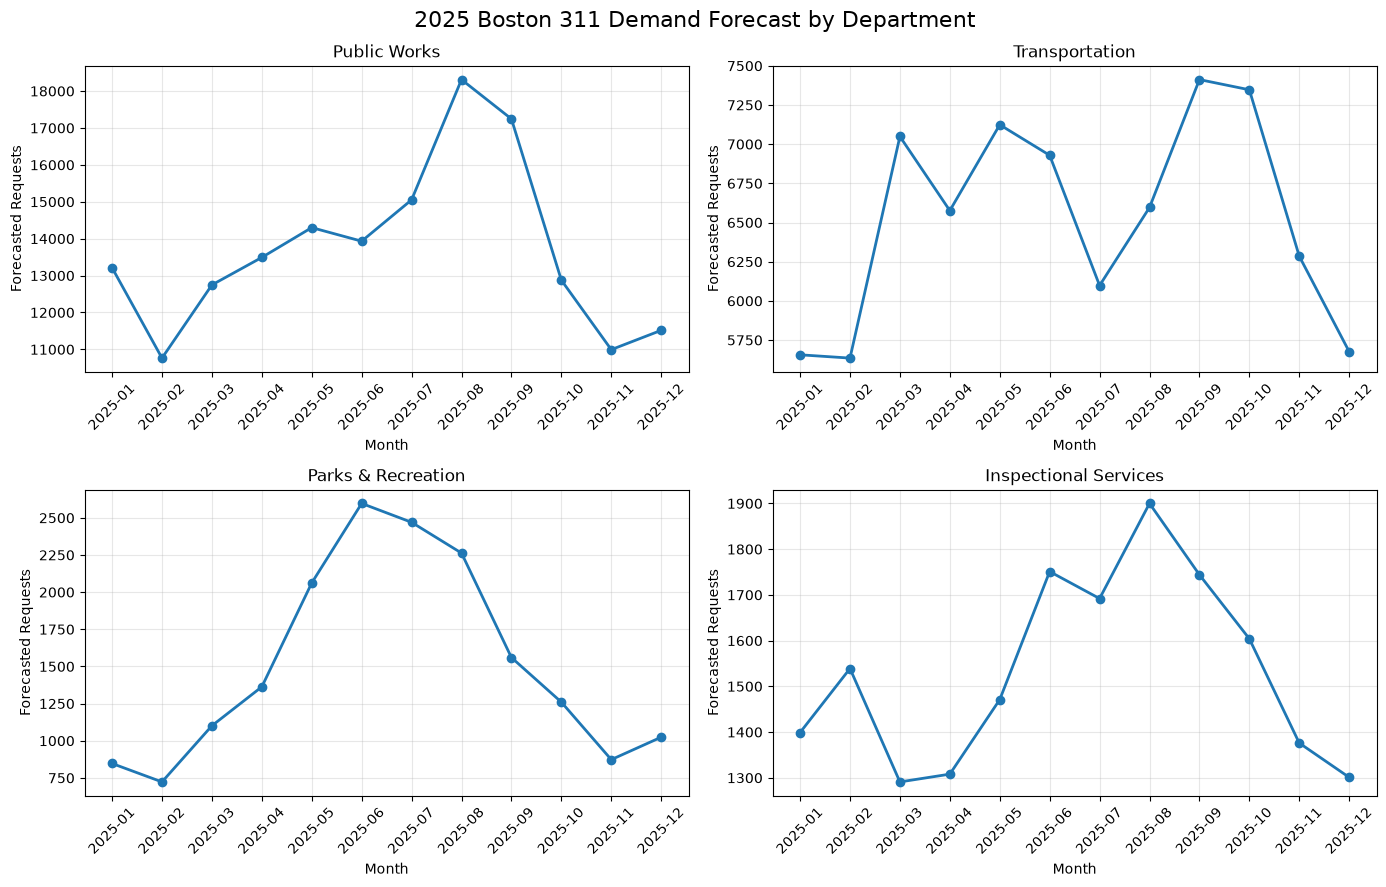

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (code, name) in zip(
    axes.flatten(), department_names.items()
):
    subset = final_forecast[
        final_forecast["department"] == code
    ]

    ax.plot(
        subset["month"],
        subset["forecast_requests"],
        marker="o",
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel("Month")
    ax.set_ylabel("Forecasted Requests")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.suptitle(
    "2025 Boston 311 Demand Forecast by Department",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [21]:
# Final forecast checks
assert len(final_forecast) == 48
assert final_forecast[["department", "month"]].duplicated().sum() == 0
assert final_forecast["forecast_requests"].notna().all()
assert (final_forecast["forecast_requests"] >= 0).all()

print("Forecast validation passed!")

print("\nAnnual forecast by department:")
display(
    final_forecast.groupby("department")["forecast_requests"]
    .sum().to_frame("2025_forecast")
)

print("\nTotal forecasted requests:",
      final_forecast["forecast_requests"].sum())

Forecast validation passed!

Annual forecast by department:


,2025_forecast
department,
BTDT,78383
ISD,18376
PARK,18143
PWDx,164441



Total forecasted requests: 279343


# Forecasting Results and Conclusions

The forecasting process produced 48 monthly demand predictions for 2025, covering four departments over 12 months.

Department vs. Forecasted 2025 Requests

Public Works: 164,441

Transportation: 78,383

Parks & Recreation: 18,143

Inspectional Services: 18,376

Total: 279,343

The results indicate that Public Works accounts for the largest share of expected service demand, while Parks & Recreation experiences particularly strong seasonal variation.

These observations suggest that a dynamic staffing strategy may be more suitable than maintaining constant crew levels across all months.

# Limitations

The forecast is based on two years of historical data, which limits the ability to distinguish long-term trends from short-term fluctuations. The model also does not explicitly incorporate unexpected weather events, changes in resident reporting behavior, or external factors that could influence service demand.

Additionally, forecasted request counts represent incoming workload, not the exact number of requests that can be completed within service-level deadlines.

# Integration With Staffing Optimization

The final forecast is exported as boston_311_2025_forecast.csv, containing the columns department, month, and forecast_requests.

The file contains one row per department-month combination and is designed to be imported directly into the staffing optimization component.

A separate demand sensitivity dataset provides baseline, low-demand, and high-demand estimates for evaluating staffing decisions under uncertainty.

The forecasting results provide the demand inputs needed to determine monthly crew requirements, evaluate hiring decisions, and analyze the tradeoff between staffing costs and service performance.

# PART 2: Staffing assumptions and capacity-only crew requirements

In [22]:

# Validate the Part 1 forecast input
required_columns = {"department", "month", "forecast_requests"}
expected_departments = {"PWDx", "BTDT", "PARK", "ISD"}
expected_annual_totals = {
    "PWDx": 164441,
    "BTDT": 78383,
    "PARK": 18143,
    "ISD": 18376
}

assert required_columns.issubset(final_forecast.columns)
assert set(final_forecast["department"]) == expected_departments
assert len(final_forecast) == 48
assert final_forecast[["department", "month"]].duplicated().sum() == 0
assert final_forecast["forecast_requests"].notna().all()

actual_annual_totals = (
    final_forecast.groupby("department")["forecast_requests"]
    .sum()
    .to_dict()
)

assert actual_annual_totals == expected_annual_totals
assert final_forecast["forecast_requests"].sum() == 279343

# Exact assumptions from the Boston 311 brief
staffing_assumptions = pd.DataFrame({
    "department": ["PWDx", "BTDT", "PARK", "ISD"],
    "daily_capacity_per_crew": [12, 15, 6, 4],
    "annual_cost_per_crew": [130000, 110000, 120000, 140000],
    "starting_crews": [50, 18, 10, 16]
})

WORKDAYS_PER_MONTH = 21
HIRING_TRAINING_DELAY_MONTHS = 1
RELEASE_NOTICE_MONTHS = 1
RELEASE_COST_RATE = 0.25

PARK_SEASONAL_START_MONTH = 4
PARK_SEASONAL_END_MONTH = 10
PARK_SEASONAL_COST_MULTIPLIER = 1.3

OVERDUE_REQUEST_COST = 20
EXTRA_30_DAY_OVERDUE_COST = 100

# Build the monthly staffing input table
staffing_inputs = final_forecast.copy()
staffing_inputs["month"] = pd.to_datetime(
    staffing_inputs["month"],
    format="%Y-%m"
)

staffing_inputs = staffing_inputs.merge(
    staffing_assumptions,
    on="department",
    how="left",
    validate="many_to_one"
)

staffing_inputs["monthly_capacity_per_crew"] = (
    staffing_inputs["daily_capacity_per_crew"]
    * WORKDAYS_PER_MONTH
)

staffing_inputs["regular_monthly_cost_per_crew"] = (
    staffing_inputs["annual_cost_per_crew"] / 12
)

staffing_inputs["required_crews_capacity_only"] = np.ceil(
    staffing_inputs["forecast_requests"]
    / staffing_inputs["monthly_capacity_per_crew"]
).astype(int)

staffing_inputs["crew_gap_vs_jan_start"] = (
    staffing_inputs["required_crews_capacity_only"]
    - staffing_inputs["starting_crews"]
)

staffing_inputs["starting_capacity"] = (
    staffing_inputs["starting_crews"]
    * staffing_inputs["monthly_capacity_per_crew"]
)

staffing_inputs["backlog_if_starting_crews_held"] = np.maximum(
    staffing_inputs["forecast_requests"]
    - staffing_inputs["starting_capacity"],
    0
)

display(
    staffing_inputs[
        [
            "department",
            "month",
            "forecast_requests",
            "monthly_capacity_per_crew",
            "starting_crews",
            "required_crews_capacity_only",
            "crew_gap_vs_jan_start",
            "backlog_if_starting_crews_held"
        ]
    ].sort_values(["month", "department"])
)

print(
    "Capacity requirements calculated. "
    "Hiring delays, release notices, seasonal crews, costs, "
    "and rolling backlog will be applied in the next step."
)

,department,month,forecast_requests,monthly_capacity_per_crew,starting_crews,required_crews_capacity_only,crew_gap_vs_jan_start,backlog_if_starting_crews_held
0,BTDT,2025-01-01,5656,315,18,18,0,0
12,ISD,2025-01-01,1399,84,16,17,1,55
24,PARK,2025-01-01,847,126,10,7,-3,0
36,PWDx,2025-01-01,13213,252,50,53,3,613
1,BTDT,2025-02-01,5635,315,18,18,0,0
13,ISD,2025-02-01,1539,84,16,19,3,195
25,PARK,2025-02-01,723,126,10,6,-4,0
37,PWDx,2025-02-01,10764,252,50,43,-7,0
2,BTDT,2025-03-01,7049,315,18,23,5,1379
14,ISD,2025-03-01,1291,84,16,16,0,0


Capacity requirements calculated. Hiring delays, release notices, seasonal crews, costs, and rolling backlog will be applied in the next step.


###Initial Staffing Capacity Analysis

This step validates the 2025 forecast before using it in the staffing model. The forecast contains 48 unique department-month records, with no missing demand values or duplicate department-month combinations. Total forecasted demand is 279,343 requests.

The staffing assumptions are taken directly from the Boston 311 brief. Each crew works 21 days per month, and department-specific daily capacities, annual costs, and January starting crew levels are applied.

The initial crew requirement is calculated as:

**Required crews = Monthly forecast requests ÷ Monthly capacity per crew, rounded up**

The January comparison shows:

- Public Works requires 53 crews compared with 50 available, creating a preliminary shortage of 3 crews.
- Transportation requires 18 crews, equal to its starting workforce.
- Parks requires 7 crews compared with 10 available, indicating surplus winter capacity.
- Inspectional Services requires 17 crews compared with 16 available, creating a preliminary shortage of 1 crew.

If January staffing were held constant throughout the year, several departments would develop backlogs during peak-demand months. These results are capacity-only estimates. They do not yet account for the one-month hiring delay, release notice, release costs, Parks seasonal crews, or rolling backlog. Those constraints are incorporated in the next stage of the staffing model.

In [23]:
# PART 2 — Lifecycle setup and January baseline


lifecycle_inputs = (
    staffing_inputs
    .sort_values(["department", "month"])
    .reset_index(drop=True)
    .copy()
)

# Monthly regular crew cost
lifecycle_inputs["regular_monthly_cost_per_crew"] = (
    lifecycle_inputs["annual_cost_per_crew"] / 12
)

# Seasonal Parks crews cost 1.3 times the regular monthly cost
lifecycle_inputs["seasonal_monthly_cost_per_crew"] = (
    lifecycle_inputs["regular_monthly_cost_per_crew"]
    * PARK_SEASONAL_COST_MULTIPLIER
)

# Identify months when seasonal Parks crews are allowed
lifecycle_inputs["seasonal_allowed"] = (
    (lifecycle_inputs["department"] == "PARK")
    & (
        lifecycle_inputs["month"].dt.month
        .between(
            PARK_SEASONAL_START_MONTH,
            PARK_SEASONAL_END_MONTH
        )
    )
)

display(
    lifecycle_inputs[
        [
            "department",
            "month",
            "forecast_requests",
            "starting_crews",
            "monthly_capacity_per_crew",
            "regular_monthly_cost_per_crew",
            "seasonal_monthly_cost_per_crew",
            "seasonal_allowed"
        ]
    ].head(16)
)

print("Lifecycle staffing inputs prepared.")


january_plan = lifecycle_inputs[
    lifecycle_inputs["month"].dt.month == 1
].copy()

# January starts with the crew levels given in the brief
january_plan["regular_crews"] = (
    january_plan["starting_crews"]
)

# Seasonal Parks crews are unavailable in January
january_plan["seasonal_crews"] = 0

# The brief states that no requests are waiting
# at the beginning of 2025
january_plan["opening_backlog"] = 0

january_plan["total_capacity"] = (
    january_plan["regular_crews"]
    * january_plan["monthly_capacity_per_crew"]
)

january_plan["ending_backlog"] = np.maximum(
    january_plan["forecast_requests"]
    - january_plan["total_capacity"],
    0
)

january_plan["requests_closed_on_time"] = (
    january_plan["forecast_requests"]
    - january_plan["ending_backlog"]
)

january_plan["estimated_on_time_rate"] = (
    january_plan["requests_closed_on_time"]
    / january_plan["forecast_requests"]
)

january_plan["regular_staffing_cost"] = (
    january_plan["regular_crews"]
    * january_plan["regular_monthly_cost_per_crew"]
)

january_plan["overdue_cost"] = (
    january_plan["ending_backlog"]
    * OVERDUE_REQUEST_COST
)

january_plan["total_january_cost"] = (
    january_plan["regular_staffing_cost"]
    + january_plan["overdue_cost"]
)

display(
    january_plan[
        [
            "department",
            "forecast_requests",
            "regular_crews",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "regular_staffing_cost",
            "overdue_cost",
            "total_january_cost"
        ]
    ].sort_values("department")
)


,department,month,forecast_requests,starting_crews,monthly_capacity_per_crew,regular_monthly_cost_per_crew,seasonal_monthly_cost_per_crew,seasonal_allowed
0,BTDT,2025-01-01,5656,18,315,9166.666667,11916.666667,False
1,BTDT,2025-02-01,5635,18,315,9166.666667,11916.666667,False
2,BTDT,2025-03-01,7049,18,315,9166.666667,11916.666667,False
3,BTDT,2025-04-01,6576,18,315,9166.666667,11916.666667,False
4,BTDT,2025-05-01,7124,18,315,9166.666667,11916.666667,False
5,BTDT,2025-06-01,6929,18,315,9166.666667,11916.666667,False
6,BTDT,2025-07-01,6098,18,315,9166.666667,11916.666667,False
7,BTDT,2025-08-01,6596,18,315,9166.666667,11916.666667,False
8,BTDT,2025-09-01,7412,18,315,9166.666667,11916.666667,False
9,BTDT,2025-10-01,7347,18,315,9166.666667,11916.666667,False


Lifecycle staffing inputs prepared.


,department,forecast_requests,regular_crews,total_capacity,ending_backlog,estimated_on_time_rate,regular_staffing_cost,overdue_cost,total_january_cost
0,BTDT,5656,18,5670,0,1.000000,165000.000000,0,165000.000000
12,ISD,1399,16,1344,55,0.960686,186666.666667,1100,187766.666667
24,PARK,847,10,1260,0,1.000000,100000.000000,0,100000.000000
36,PWDx,13213,50,12600,613,0.953606,541666.666667,12260,553926.666667


### Lifecycle setup and January baseline

Annual crew costs are converted to monthly costs, Parks seasonal eligibility is limited to April–October, and January starts with the exact crew levels from the brief and zero opening backlog. January shortages create 613 backlogged Public Works requests and 55 Inspectional Services requests; Transportation and Parks finish January without backlog.

In [24]:
# PART 2 — January decisions and February results


january_state = (
    january_plan[
        [
            "department",
            "regular_crews",
            "ending_backlog"
        ]
    ]
    .rename(
        columns={
            "regular_crews":
                "january_regular_crews",
            "ending_backlog":
                "january_ending_backlog"
        }
    )
)

february_hiring_plan = (
    lifecycle_inputs[
        lifecycle_inputs["month"].dt.month == 2
    ]
    .merge(
        january_state,
        on="department",
        how="left",
        validate="one_to_one"
    )
)

# February must process January backlog
# before processing February requests
february_hiring_plan[
    "february_total_workload"
] = (
    february_hiring_plan[
        "forecast_requests"
    ]
    + february_hiring_plan[
        "january_ending_backlog"
    ]
)

february_hiring_plan[
    "required_crews_february"
] = np.ceil(
    february_hiring_plan[
        "february_total_workload"
    ]
    / february_hiring_plan[
        "monthly_capacity_per_crew"
    ]
).astype(int)

# Crews hired in January become available in February
february_hiring_plan[
    "hires_started_in_january"
] = np.maximum(
    february_hiring_plan[
        "required_crews_february"
    ]
    - february_hiring_plan[
        "january_regular_crews"
    ],
    0
)

february_hiring_plan[
    "february_regular_crews"
] = (
    february_hiring_plan[
        "january_regular_crews"
    ]
    + february_hiring_plan[
        "hires_started_in_january"
    ]
)

display(
    february_hiring_plan[
        [
            "department",
            "forecast_requests",
            "january_ending_backlog",
            "february_total_workload",
            "january_regular_crews",
            "required_crews_february",
            "hires_started_in_january",
            "february_regular_crews"
        ]
    ].sort_values("department")
)


february_plan = february_hiring_plan.copy()

february_plan["regular_crews"] = (
    february_plan["february_regular_crews"]
)

february_plan["seasonal_crews"] = 0

february_plan["opening_backlog"] = (
    february_plan["january_ending_backlog"]
)

february_plan["total_capacity"] = (
    february_plan["regular_crews"]
    * february_plan["monthly_capacity_per_crew"]
)

february_plan["ending_backlog"] = np.maximum(
    february_plan["february_total_workload"]
    - february_plan["total_capacity"],
    0
)

# Old backlog is completed before February requests
february_plan["capacity_for_new_requests"] = (
    np.maximum(
        february_plan["total_capacity"]
        - february_plan["opening_backlog"],
        0
    )
)

february_plan["requests_closed_on_time"] = np.minimum(
    february_plan["forecast_requests"],
    february_plan["capacity_for_new_requests"]
)

february_plan["estimated_on_time_rate"] = (
    february_plan["requests_closed_on_time"]
    / february_plan["forecast_requests"]
)

# Backlog that remains open for another month
february_plan["backlog_over_30_days"] = np.maximum(
    february_plan["opening_backlog"]
    - february_plan["total_capacity"],
    0
)

february_plan["regular_staffing_cost"] = (
    february_plan["regular_crews"]
    * february_plan["regular_monthly_cost_per_crew"]
)

february_plan["overdue_cost"] = (
    february_plan["ending_backlog"]
    * OVERDUE_REQUEST_COST
)

february_plan["extra_30_day_cost"] = (
    february_plan["backlog_over_30_days"]
    * EXTRA_30_DAY_OVERDUE_COST
)

february_plan["total_february_cost"] = (
    february_plan["regular_staffing_cost"]
    + february_plan["overdue_cost"]
    + february_plan["extra_30_day_cost"]
)

display(
    february_plan[
        [
            "department",
            "forecast_requests",
            "opening_backlog",
            "regular_crews",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "regular_staffing_cost",
            "overdue_cost",
            "extra_30_day_cost",
            "total_february_cost"
        ]
    ].sort_values("department")
)


,department,forecast_requests,january_ending_backlog,february_total_workload,january_regular_crews,required_crews_february,hires_started_in_january,february_regular_crews
0,BTDT,5635,0,5635,18,18,0,18
1,ISD,1539,55,1594,16,19,3,19
2,PARK,723,0,723,10,6,0,10
3,PWDx,10764,613,11377,50,46,0,50


,department,forecast_requests,opening_backlog,regular_crews,total_capacity,ending_backlog,estimated_on_time_rate,regular_staffing_cost,overdue_cost,extra_30_day_cost,total_february_cost
0,BTDT,5635,0,18,5670,0,1.0,165000.000000,0,0,165000.000000
1,ISD,1539,55,19,1596,0,1.0,221666.666667,0,0,221666.666667
2,PARK,723,0,10,1260,0,1.0,100000.000000,0,0,100000.000000
3,PWDx,10764,613,50,12600,0,1.0,541666.666667,0,0,541666.666667


### January decisions and February results

Because regular crews require one month of hiring and training, January hiring is based on February demand plus January backlog. Inspectional Services hires three crews for February; the other departments make no January hires. February capacity clears all January backlog, so no request remains open for more than 30 days.

In [25]:
# PART 2 — February decisions and March results


february_state = (
    february_plan[
        [
            "department",
            "regular_crews",
            "ending_backlog"
        ]
    ]
    .rename(
        columns={
            "regular_crews":
                "february_regular_crews",
            "ending_backlog":
                "february_ending_backlog"
        }
    )
)

march_hiring_plan = (
    lifecycle_inputs[
        lifecycle_inputs["month"].dt.month == 3
    ]
    .merge(
        february_state,
        on="department",
        how="left",
        validate="one_to_one"
    )
)

march_hiring_plan["march_total_workload"] = (
    march_hiring_plan["forecast_requests"]
    + march_hiring_plan["february_ending_backlog"]
)

march_hiring_plan["required_crews_march"] = np.ceil(
    march_hiring_plan["march_total_workload"]
    / march_hiring_plan["monthly_capacity_per_crew"]
).astype(int)

# Crews hired during February become available in March
march_hiring_plan["hires_started_in_february"] = (
    np.maximum(
        march_hiring_plan["required_crews_march"]
        - march_hiring_plan["february_regular_crews"],
        0
    )
)

march_hiring_plan["march_regular_crews"] = (
    march_hiring_plan["february_regular_crews"]
    + march_hiring_plan["hires_started_in_february"]
)

display(
    march_hiring_plan[
        [
            "department",
            "forecast_requests",
            "february_ending_backlog",
            "march_total_workload",
            "february_regular_crews",
            "required_crews_march",
            "hires_started_in_february",
            "march_regular_crews"
        ]
    ].sort_values("department")
)


march_plan = march_hiring_plan.copy()

march_plan["regular_crews"] = (
    march_plan["march_regular_crews"]
)

march_plan["seasonal_crews"] = 0

march_plan["opening_backlog"] = (
    march_plan["february_ending_backlog"]
)

march_plan["total_capacity"] = (
    march_plan["regular_crews"]
    * march_plan["monthly_capacity_per_crew"]
)

march_plan["ending_backlog"] = np.maximum(
    march_plan["march_total_workload"]
    - march_plan["total_capacity"],
    0
)

march_plan["capacity_for_new_requests"] = np.maximum(
    march_plan["total_capacity"]
    - march_plan["opening_backlog"],
    0
)

march_plan["requests_closed_on_time"] = np.minimum(
    march_plan["forecast_requests"],
    march_plan["capacity_for_new_requests"]
)

march_plan["estimated_on_time_rate"] = (
    march_plan["requests_closed_on_time"]
    / march_plan["forecast_requests"]
)

march_plan["backlog_over_30_days"] = np.maximum(
    march_plan["opening_backlog"]
    - march_plan["total_capacity"],
    0
)

march_plan["regular_staffing_cost"] = (
    march_plan["regular_crews"]
    * march_plan["regular_monthly_cost_per_crew"]
)

march_plan["overdue_cost"] = (
    march_plan["ending_backlog"]
    * OVERDUE_REQUEST_COST
)

march_plan["extra_30_day_cost"] = (
    march_plan["backlog_over_30_days"]
    * EXTRA_30_DAY_OVERDUE_COST
)

march_plan["total_march_cost"] = (
    march_plan["regular_staffing_cost"]
    + march_plan["overdue_cost"]
    + march_plan["extra_30_day_cost"]
)

display(
    march_plan[
        [
            "department",
            "forecast_requests",
            "opening_backlog",
            "regular_crews",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "regular_staffing_cost",
            "overdue_cost",
            "extra_30_day_cost",
            "total_march_cost"
        ]
    ].sort_values("department")
)


,department,forecast_requests,february_ending_backlog,march_total_workload,february_regular_crews,required_crews_march,hires_started_in_february,march_regular_crews
0,BTDT,7049,0,7049,18,23,5,23
1,ISD,1291,0,1291,19,16,0,19
2,PARK,1101,0,1101,10,9,0,10
3,PWDx,12747,0,12747,50,51,1,51


,department,forecast_requests,opening_backlog,regular_crews,total_capacity,ending_backlog,estimated_on_time_rate,regular_staffing_cost,overdue_cost,extra_30_day_cost,total_march_cost
0,BTDT,7049,0,23,7245,0,1.0,210833.333333,0,0,210833.333333
1,ISD,1291,0,19,1596,0,1.0,221666.666667,0,0,221666.666667
2,PARK,1101,0,10,1260,0,1.0,100000.000000,0,0,100000.000000
3,PWDx,12747,0,51,12852,0,1.0,552500.000000,0,0,552500.000000


### February decisions and March results

February hiring prepares the March workforce: Transportation adds five crews and Public Works adds one, while Parks and Inspectional Services retain their existing levels. The resulting March capacity completes all forecasted demand with no ending backlog.

In [26]:
# PART 2 — March decisions and April seasonal staffing


march_state = (
    march_plan[
        [
            "department",
            "regular_crews",
            "ending_backlog"
        ]
    ]
    .rename(
        columns={
            "regular_crews":
                "march_regular_crews",
            "ending_backlog":
                "march_ending_backlog"
        }
    )
)

april_staffing_plan = (
    lifecycle_inputs[
        lifecycle_inputs["month"].dt.month == 4
    ]
    .merge(
        march_state,
        on="department",
        how="left",
        validate="one_to_one"
    )
)

april_staffing_plan["april_total_workload"] = (
    april_staffing_plan["forecast_requests"]
    + april_staffing_plan["march_ending_backlog"]
)

april_staffing_plan[
    "required_crews_april"
] = np.ceil(
    april_staffing_plan["april_total_workload"]
    / april_staffing_plan[
        "monthly_capacity_per_crew"
    ]
).astype(int)

# Regular crews hired in March become available in April.
# Parks uses seasonal crews instead of regular hiring
# during the April–October seasonal period.
april_staffing_plan[
    "hires_started_in_march"
] = np.where(
    april_staffing_plan["department"] == "PARK",
    0,
    np.maximum(
        april_staffing_plan["required_crews_april"]
        - april_staffing_plan["march_regular_crews"],
        0
    )
).astype(int)

april_staffing_plan["april_regular_crews"] = (
    april_staffing_plan["march_regular_crews"]
    + april_staffing_plan["hires_started_in_march"]
)

april_staffing_plan[
    "april_regular_capacity"
] = (
    april_staffing_plan["april_regular_crews"]
    * april_staffing_plan[
        "monthly_capacity_per_crew"
    ]
)

# Seasonal Parks crews have no training delay
seasonal_capacity_gap = np.maximum(
    april_staffing_plan["april_total_workload"]
    - april_staffing_plan[
        "april_regular_capacity"
    ],
    0
)

april_staffing_plan[
    "april_seasonal_crews"
] = np.where(
    april_staffing_plan["seasonal_allowed"],
    np.ceil(
        seasonal_capacity_gap
        / april_staffing_plan[
            "monthly_capacity_per_crew"
        ]
    ),
    0
).astype(int)

display(
    april_staffing_plan[
        [
            "department",
            "forecast_requests",
            "march_ending_backlog",
            "march_regular_crews",
            "required_crews_april",
            "hires_started_in_march",
            "april_regular_crews",
            "seasonal_allowed",
            "april_seasonal_crews"
        ]
    ].sort_values("department")
)


april_plan = april_staffing_plan.copy()

april_plan["regular_crews"] = (
    april_plan["april_regular_crews"]
)

april_plan["seasonal_crews"] = (
    april_plan["april_seasonal_crews"]
)

april_plan["opening_backlog"] = (
    april_plan["march_ending_backlog"]
)

april_plan["total_capacity"] = (
    (
        april_plan["regular_crews"]
        + april_plan["seasonal_crews"]
    )
    * april_plan["monthly_capacity_per_crew"]
)

april_plan["ending_backlog"] = np.maximum(
    april_plan["april_total_workload"]
    - april_plan["total_capacity"],
    0
)

april_plan["capacity_for_new_requests"] = np.maximum(
    april_plan["total_capacity"]
    - april_plan["opening_backlog"],
    0
)

april_plan["requests_closed_on_time"] = np.minimum(
    april_plan["forecast_requests"],
    april_plan["capacity_for_new_requests"]
)

april_plan["estimated_on_time_rate"] = (
    april_plan["requests_closed_on_time"]
    / april_plan["forecast_requests"]
)

april_plan["backlog_over_30_days"] = np.maximum(
    april_plan["opening_backlog"]
    - april_plan["total_capacity"],
    0
)

april_plan["regular_staffing_cost"] = (
    april_plan["regular_crews"]
    * april_plan["regular_monthly_cost_per_crew"]
)

april_plan["seasonal_staffing_cost"] = (
    april_plan["seasonal_crews"]
    * april_plan["seasonal_monthly_cost_per_crew"]
)

april_plan["overdue_cost"] = (
    april_plan["ending_backlog"]
    * OVERDUE_REQUEST_COST
)

april_plan["extra_30_day_cost"] = (
    april_plan["backlog_over_30_days"]
    * EXTRA_30_DAY_OVERDUE_COST
)

april_plan["total_april_cost"] = (
    april_plan["regular_staffing_cost"]
    + april_plan["seasonal_staffing_cost"]
    + april_plan["overdue_cost"]
    + april_plan["extra_30_day_cost"]
)

display(
    april_plan[
        [
            "department",
            "forecast_requests",
            "opening_backlog",
            "regular_crews",
            "seasonal_crews",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "regular_staffing_cost",
            "seasonal_staffing_cost",
            "total_april_cost"
        ]
    ].sort_values("department")
)


,department,forecast_requests,march_ending_backlog,march_regular_crews,required_crews_april,hires_started_in_march,april_regular_crews,seasonal_allowed,april_seasonal_crews
0,BTDT,6576,0,23,21,0,23,False,0
1,ISD,1308,0,19,16,0,19,False,0
2,PARK,1363,0,10,11,0,10,True,1
3,PWDx,13492,0,51,54,3,54,False,0


,department,forecast_requests,opening_backlog,regular_crews,seasonal_crews,total_capacity,ending_backlog,estimated_on_time_rate,regular_staffing_cost,seasonal_staffing_cost,total_april_cost
0,BTDT,6576,0,23,0,7245,0,1.0,210833.333333,0.0,210833.333333
1,ISD,1308,0,19,0,1596,0,1.0,221666.666667,0.0,221666.666667
2,PARK,1363,0,10,1,1386,0,1.0,100000.000000,13000.0,113000.000000
3,PWDx,13492,0,54,0,13608,0,1.0,585000.000000,0.0,585000.000000


### March decisions and April seasonal staffing

March decisions establish April regular staffing after the required one-month delay. April is also the first month in which Parks may use seasonal crews, costed at 1.3 times the regular monthly crew cost. Capacity, backlog, service rate, and all monthly cost components are calculated consistently.

In [27]:
# PART 2 — Reusable monthly staffing and cost functions


def prepare_month_staffing(
    month_number,
    previous_month_plan
):

    current_month = (
        lifecycle_inputs[
            lifecycle_inputs["month"].dt.month
            == month_number
        ]
        .copy()
    )

    previous_state = (
        previous_month_plan[
            [
                "department",
                "regular_crews",
                "ending_backlog"
            ]
        ]
        .rename(
            columns={
                "regular_crews":
                    "previous_regular_crews",
                "ending_backlog":
                    "opening_backlog"
            }
        )
    )

    current_month = current_month.merge(
        previous_state,
        on="department",
        how="left",
        validate="one_to_one"
    )

    current_month["total_workload"] = (
        current_month["forecast_requests"]
        + current_month["opening_backlog"]
    )

    current_month["required_crews"] = np.ceil(
        current_month["total_workload"]
        / current_month[
            "monthly_capacity_per_crew"
        ]
    ).astype(int)

    # Regular crews needed this month must have been
    # hired during the previous month.
    # Parks uses seasonal crews during April–October.
    current_month[
        "hires_started_previous_month"
    ] = np.where(
        current_month["seasonal_allowed"],
        0,
        np.maximum(
            current_month["required_crews"]
            - current_month[
                "previous_regular_crews"
            ],
            0
        )
    ).astype(int)

    current_month["regular_crews"] = (
        current_month["previous_regular_crews"]
        + current_month[
            "hires_started_previous_month"
        ]
    )

    current_month["regular_capacity"] = (
        current_month["regular_crews"]
        * current_month[
            "monthly_capacity_per_crew"
        ]
    )

    seasonal_capacity_gap = np.maximum(
        current_month["total_workload"]
        - current_month["regular_capacity"],
        0
    )

    current_month["seasonal_crews"] = np.where(
        current_month["seasonal_allowed"],
        np.ceil(
            seasonal_capacity_gap
            / current_month[
                "monthly_capacity_per_crew"
            ]
        ),
        0
    ).astype(int)

    return current_month


print("Reusable monthly staffing function created.")


def calculate_month_results(
    prepared_month_plan
):

    monthly_result = (
        prepared_month_plan.copy()
    )

    monthly_result["total_capacity"] = (
        (
            monthly_result["regular_crews"]
            + monthly_result["seasonal_crews"]
        )
        * monthly_result[
            "monthly_capacity_per_crew"
        ]
    )

    monthly_result["ending_backlog"] = np.maximum(
        monthly_result["total_workload"]
        - monthly_result["total_capacity"],
        0
    )

    # Previous backlog is processed before
    # the current month's new requests
    monthly_result[
        "capacity_for_new_requests"
    ] = np.maximum(
        monthly_result["total_capacity"]
        - monthly_result["opening_backlog"],
        0
    )

    monthly_result[
        "requests_closed_on_time"
    ] = np.minimum(
        monthly_result["forecast_requests"],
        monthly_result[
            "capacity_for_new_requests"
        ]
    )

    monthly_result[
        "estimated_on_time_rate"
    ] = (
        monthly_result[
            "requests_closed_on_time"
        ]
        / monthly_result["forecast_requests"]
    )

    # Backlog remaining after another month
    # receives the additional $100 penalty
    monthly_result[
        "backlog_over_30_days"
    ] = np.maximum(
        monthly_result["opening_backlog"]
        - monthly_result["total_capacity"],
        0
    )

    monthly_result[
        "regular_staffing_cost"
    ] = (
        monthly_result["regular_crews"]
        * monthly_result[
            "regular_monthly_cost_per_crew"
        ]
    )

    monthly_result[
        "seasonal_staffing_cost"
    ] = (
        monthly_result["seasonal_crews"]
        * monthly_result[
            "seasonal_monthly_cost_per_crew"
        ]
    )

    monthly_result["overdue_cost"] = (
        monthly_result["ending_backlog"]
        * OVERDUE_REQUEST_COST
    )

    monthly_result["extra_30_day_cost"] = (
        monthly_result[
            "backlog_over_30_days"
        ]
        * EXTRA_30_DAY_OVERDUE_COST
    )

    monthly_result["total_monthly_cost"] = (
        monthly_result[
            "regular_staffing_cost"
        ]
        + monthly_result[
            "seasonal_staffing_cost"
        ]
        + monthly_result["overdue_cost"]
        + monthly_result[
            "extra_30_day_cost"
        ]
    )

    return monthly_result


print(
    "Monthly backlog and cost function created."
)


Reusable monthly staffing function created.
Monthly backlog and cost function created.


### Reusable baseline functions

The two functions apply the same workforce timing, seasonal eligibility, backlog flow, on-time-rate, and cost rules to every remaining month. This replaces repeated month-specific code while preserving the brief’s one-month hiring delay, release notice, seasonal window, and overdue penalties.

In [28]:
# PART 2 — Run and assemble the May–December baseline


remaining_month_results = []

previous_month_plan = april_plan.copy()

for month_number in range(5, 13):

    prepared_month = prepare_month_staffing(
        month_number,
        previous_month_plan
    )

    completed_month = calculate_month_results(
        prepared_month
    )

    remaining_month_results.append(
        completed_month
    )

    previous_month_plan = completed_month


may_to_december_plan = (
    pd.concat(
        remaining_month_results,
        ignore_index=True
    )
    .sort_values([
        "month",
        "department"
    ])
    .reset_index(drop=True)
)


display(
    may_to_december_plan[
        [
            "department",
            "month",
            "forecast_requests",
            "opening_backlog",
            "hires_started_previous_month",
            "regular_crews",
            "seasonal_crews",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "total_monthly_cost"
        ]
    ]
)


baseline_columns = [
    "department",
    "month",
    "forecast_requests",
    "opening_backlog",
    "regular_crews",
    "seasonal_crews",
    "hires_effective",
    "releases_effective",
    "total_capacity",
    "ending_backlog",
    "estimated_on_time_rate",
    "regular_staffing_cost",
    "seasonal_staffing_cost",
    "release_cost",
    "overdue_cost",
    "extra_30_day_cost",
    "total_monthly_cost"
]


def standardize_baseline_month(
    month_plan,
    hire_column,
    total_cost_column
):

    standardized = month_plan.copy()

    if hire_column is None:
        standardized["hires_effective"] = 0
    else:
        standardized["hires_effective"] = (
            standardized[hire_column]
        )

    if "seasonal_crews" not in standardized.columns:
        standardized["seasonal_crews"] = 0

    if (
        "seasonal_staffing_cost"
        not in standardized.columns
    ):
        standardized["seasonal_staffing_cost"] = 0

    if (
        "extra_30_day_cost"
        not in standardized.columns
    ):
        standardized["extra_30_day_cost"] = 0

    standardized["releases_effective"] = 0
    standardized["release_cost"] = 0

    standardized["total_monthly_cost"] = (
        standardized[total_cost_column]
    )

    return standardized[baseline_columns]


january_standard = standardize_baseline_month(
    january_plan,
    hire_column=None,
    total_cost_column="total_january_cost"
)

february_standard = standardize_baseline_month(
    february_plan,
    hire_column="hires_started_in_january",
    total_cost_column="total_february_cost"
)

march_standard = standardize_baseline_month(
    march_plan,
    hire_column="hires_started_in_february",
    total_cost_column="total_march_cost"
)

april_standard = standardize_baseline_month(
    april_plan,
    hire_column="hires_started_in_march",
    total_cost_column="total_april_cost"
)

remaining_standard = standardize_baseline_month(
    may_to_december_plan,
    hire_column="hires_started_previous_month",
    total_cost_column="total_monthly_cost"
)


baseline_staffing_plan = (
    pd.concat(
        [
            january_standard,
            february_standard,
            march_standard,
            april_standard,
            remaining_standard
        ],
        ignore_index=True
    )
    .sort_values([
        "month",
        "department"
    ])
    .reset_index(drop=True)
)


# Validate the complete plan
assert len(baseline_staffing_plan) == 48

assert (
    baseline_staffing_plan[
        ["department", "month"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert (
    baseline_staffing_plan["month"]
    .dt.month
    .nunique()
    == 12
)

display(
    baseline_staffing_plan[
        [
            "department",
            "month",
            "forecast_requests",
            "regular_crews",
            "seasonal_crews",
            "hires_effective",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "total_monthly_cost"
        ]
    ]
)

print(
    "Complete 12-month baseline staffing plan created."
)


,department,month,forecast_requests,opening_backlog,hires_started_previous_month,regular_crews,seasonal_crews,total_capacity,ending_backlog,estimated_on_time_rate,total_monthly_cost
0,BTDT,2025-05-01,7124,0,0,23,0,7245,0,1.0,210833.333333
1,ISD,2025-05-01,1471,0,0,19,0,1596,0,1.0,221666.666667
2,PARK,2025-05-01,2062,0,0,10,7,2142,0,1.0,191000.000000
3,PWDx,2025-05-01,14300,0,3,57,0,14364,0,1.0,617500.000000
4,BTDT,2025-06-01,6929,0,0,23,0,7245,0,1.0,210833.333333
5,ISD,2025-06-01,1751,0,2,21,0,1764,0,1.0,245000.000000
6,PARK,2025-06-01,2597,0,0,10,11,2646,0,1.0,243000.000000
7,PWDx,2025-06-01,13932,0,0,57,0,14364,0,1.0,617500.000000
8,BTDT,2025-07-01,6098,0,0,23,0,7245,0,1.0,210833.333333
9,ISD,2025-07-01,1692,0,0,21,0,1764,0,1.0,245000.000000


,department,month,forecast_requests,regular_crews,seasonal_crews,hires_effective,total_capacity,ending_backlog,estimated_on_time_rate,total_monthly_cost
0,BTDT,2025-01-01,5656,18,0,0,5670,0,1.000000,165000.000000
1,ISD,2025-01-01,1399,16,0,0,1344,55,0.960686,187766.666667
2,PARK,2025-01-01,847,10,0,0,1260,0,1.000000,100000.000000
3,PWDx,2025-01-01,13213,50,0,0,12600,613,0.953606,553926.666667
4,BTDT,2025-02-01,5635,18,0,0,5670,0,1.000000,165000.000000
5,ISD,2025-02-01,1539,19,0,3,1596,0,1.000000,221666.666667
6,PARK,2025-02-01,723,10,0,0,1260,0,1.000000,100000.000000
7,PWDx,2025-02-01,10764,50,0,0,12600,0,1.000000,541666.666667
8,BTDT,2025-03-01,7049,23,0,5,7245,0,1.000000,210833.333333
9,ISD,2025-03-01,1291,19,0,0,1596,0,1.000000,221666.666667


Complete 12-month baseline staffing plan created.


### Complete 12-month baseline plan

The reusable functions simulate May through December and combine those results with January–April. Validation confirms 48 unique department-month records. Regular crews remain after hiring, Parks seasonal crews can vary during April–October, and releases remain zero in this capacity-focused baseline because releases are evaluated by the optimizer.

In [29]:
# PART 2 — Baseline annual summary

baseline_staffing_plan[
    "estimated_on_time_requests"
] = np.floor(
    baseline_staffing_plan[
        "forecast_requests"
    ]
    * baseline_staffing_plan[
        "estimated_on_time_rate"
    ]
    + 0.5
).astype(int)

baseline_staffing_plan[
    "total_penalty_cost"
] = (
    baseline_staffing_plan["overdue_cost"]
    + baseline_staffing_plan[
        "extra_30_day_cost"
    ]
)


baseline_annual_summary = (
    baseline_staffing_plan
    .sort_values([
        "department",
        "month"
    ])
    .groupby("department")
    .agg(
        annual_requests=(
            "forecast_requests",
            "sum"
        ),
        estimated_on_time_requests=(
            "estimated_on_time_requests",
            "sum"
        ),
        peak_regular_crews=(
            "regular_crews",
            "max"
        ),
        regular_crews_hired=(
            "hires_effective",
            "sum"
        ),
        seasonal_crew_months=(
            "seasonal_crews",
            "sum"
        ),
        minimum_monthly_on_time_rate=(
            "estimated_on_time_rate",
            "min"
        ),
        year_end_backlog=(
            "ending_backlog",
            "last"
        ),
        regular_staffing_cost=(
            "regular_staffing_cost",
            "sum"
        ),
        seasonal_staffing_cost=(
            "seasonal_staffing_cost",
            "sum"
        ),
        total_penalty_cost=(
            "total_penalty_cost",
            "sum"
        ),
        total_annual_cost=(
            "total_monthly_cost",
            "sum"
        )
    )
)


baseline_annual_summary[
    "overall_on_time_rate"
] = (
    baseline_annual_summary[
        "estimated_on_time_requests"
    ]
    / baseline_annual_summary[
        "annual_requests"
    ]
)


display(
    baseline_annual_summary[
        [
            "annual_requests",
            "peak_regular_crews",
            "regular_crews_hired",
            "seasonal_crew_months",
            "minimum_monthly_on_time_rate",
            "overall_on_time_rate",
            "year_end_backlog",
            "regular_staffing_cost",
            "seasonal_staffing_cost",
            "total_penalty_cost",
            "total_annual_cost"
        ]
    ]
)


print(
    "Total baseline staffing cost:",
    f"${baseline_annual_summary['total_annual_cost'].sum():,.0f}"
)


,annual_requests,peak_regular_crews,regular_crews_hired,seasonal_crew_months,minimum_monthly_on_time_rate,overall_on_time_rate,year_end_backlog,regular_staffing_cost,seasonal_staffing_cost,total_penalty_cost,total_annual_cost
department,,,,,,,,,,,
BTDT,78383,24,6,0,1.000000,1.000000,0,2475000.0,0.0,0,2475000.0
ISD,18376,23,7,0,0.960686,0.997007,0,2905000.0,0.0,1100,2906100.0
PARK,18143,10,0,40,1.000000,1.000000,0,1200000.0,520000.0,0,1720000.0
PWDx,164441,73,23,0,0.953606,0.996272,0,8060000.0,0.0,12260,8072260.0


Total baseline staffing cost: $15,173,360


### Baseline annual results

The capacity baseline ends the year with zero backlog for every department. Public Works requires the largest regular workforce; Parks uses seasonal crew-months instead of permanently expanding its winter workforce. The annual summary reports staffing, service rates, backlog, penalties, and total cost and serves as the comparison point for optimization.

In [31]:
# PART 3 — Service targets and decision variables


historical_on_time_rates = {
    "PWDx": 0.90,
    "BTDT": 0.50,
    "PARK": 0.93,
    "ISD": 0.72
}

SERVICE_LEVEL_TARGETS = {
    "PWDx": 0.90,
    "BTDT": 0.75,
    "PARK": 0.93,
    "ISD": 0.72
}


service_target_table = pd.DataFrame({
    "department": [
        "PWDx",
        "BTDT",
        "PARK",
        "ISD"
    ]
})

service_target_table[
    "2024_historical_on_time_rate"
] = (
    service_target_table["department"]
    .map(historical_on_time_rates)
)

service_target_table[
    "2025_planning_target"
] = (
    service_target_table["department"]
    .map(SERVICE_LEVEL_TARGETS)
)

service_target_table[
    "required_improvement"
] = (
    service_target_table[
        "2025_planning_target"
    ]
    - service_target_table[
        "2024_historical_on_time_rate"
    ]
)

display(service_target_table)


from scipy.optimize import (
    milp,
    LinearConstraint,
    Bounds
)


OPTIMIZATION_VARIABLES = [
    "regular_crews",
    "crews_hired",
    "crews_released",
    "seasonal_crews",
    "ending_backlog",
    "backlog_over_30_days"
]


optimization_variable_table = pd.DataFrame({
    "variable": OPTIMIZATION_VARIABLES,
    "meaning": [
        "Regular crews available during the month",
        "Regular crews hired and trained for the next month",
        "Regular crews given notice and released next month",
        "Parks seasonal crews used during the month",
        "Requests still incomplete at the end of the month",
        "Previous-month backlog still open after another month"
    ],
    "whole_number_required": [
        True,
        True,
        True,
        True,
        False,
        False
    ]
})


MAXIMUM_CREWS = 200
NUMBER_OF_MONTHS = 12


display(optimization_variable_table)

print(
    "Optimization variables and solver prepared."
)


,department,2024_historical_on_time_rate,2025_planning_target,required_improvement
0,PWDx,0.90,0.90,0.00
1,BTDT,0.50,0.75,0.25
2,PARK,0.93,0.93,0.00
3,ISD,0.72,0.72,0.00


,variable,meaning,whole_number_required
0,regular_crews,Regular crews available during the month,True
1,crews_hired,Regular crews hired and trained for the next m...,True
2,crews_released,Regular crews given notice and released next m...,True
3,seasonal_crews,Parks seasonal crews used during the month,True
4,ending_backlog,Requests still incomplete at the end of the month,False
5,backlog_over_30_days,Previous-month backlog still open after anothe...,False


Optimization variables and solver prepared.


### Service targets and decision variables

The model maintains the reported 2024 on-time rates for Public Works (90%), Parks (93%), and Inspectional Services (72%), while setting a 75% monthly target for Transportation. Monthly variables represent active regular crews, hires, releases, Parks seasonal crews, ending backlog, and backlog older than 30 days. Crew decisions are whole numbers.

In [32]:
# PART 3 — Optimization objective, bounds, and variable indexing

VARIABLE_OFFSETS = {
    variable: position * NUMBER_OF_MONTHS
    for position, variable in enumerate(
        OPTIMIZATION_VARIABLES
    )
}


def variable_index(
    variable,
    month_index
):
    return (
        VARIABLE_OFFSETS[variable]
        + month_index
    )


def create_department_model_arrays(
    department_data
):

    department_data = (
        department_data
        .sort_values("month")
        .reset_index(drop=True)
    )

    department = department_data.loc[
        0,
        "department"
    ]

    annual_cost = float(
        department_data.loc[
            0,
            "annual_cost_per_crew"
        ]
    )

    monthly_regular_cost = annual_cost / 12

    total_variables = (
        len(OPTIMIZATION_VARIABLES)
        * NUMBER_OF_MONTHS
    )

    objective = np.zeros(total_variables)

    lower_bounds = np.zeros(total_variables)

    upper_bounds = np.full(
        total_variables,
        np.inf
    )

    integrality = np.zeros(total_variables)

    for month_index in range(
        NUMBER_OF_MONTHS
    ):

        regular_index = variable_index(
            "regular_crews",
            month_index
        )

        hire_index = variable_index(
            "crews_hired",
            month_index
        )

        release_index = variable_index(
            "crews_released",
            month_index
        )

        seasonal_index = variable_index(
            "seasonal_crews",
            month_index
        )

        backlog_index = variable_index(
            "ending_backlog",
            month_index
        )

        aged_backlog_index = variable_index(
            "backlog_over_30_days",
            month_index
        )

        # Objective-function costs
        objective[regular_index] = (
            monthly_regular_cost
        )

        objective[release_index] = (
            annual_cost
            * RELEASE_COST_RATE
        )

        objective[seasonal_index] = (
            monthly_regular_cost
            * PARK_SEASONAL_COST_MULTIPLIER
        )

        objective[backlog_index] = (
            OVERDUE_REQUEST_COST
        )

        objective[aged_backlog_index] = (
            EXTRA_30_DAY_OVERDUE_COST
        )

        # Crew variables must be whole numbers
        for crew_index in [
            regular_index,
            hire_index,
            release_index,
            seasonal_index
        ]:
            integrality[crew_index] = 1
            upper_bounds[crew_index] = (
                MAXIMUM_CREWS
            )

        month_number = int(
            department_data.loc[
                month_index,
                "month"
            ].month
        )

        seasonal_allowed = (
            department == "PARK"
            and PARK_SEASONAL_START_MONTH
            <= month_number
            <= PARK_SEASONAL_END_MONTH
        )

        if not seasonal_allowed:
            upper_bounds[seasonal_index] = 0

    # December decisions cannot become effective
    # within the 2025 planning horizon
    upper_bounds[
        variable_index(
            "crews_hired",
            NUMBER_OF_MONTHS - 1
        )
    ] = 0

    upper_bounds[
        variable_index(
            "crews_released",
            NUMBER_OF_MONTHS - 1
        )
    ] = 0

    return {
        "department_data":
            department_data,
        "department":
            department,
        "annual_cost":
            annual_cost,
        "monthly_regular_cost":
            monthly_regular_cost,
        "objective":
            objective,
        "lower_bounds":
            lower_bounds,
        "upper_bounds":
            upper_bounds,
        "integrality":
            integrality
    }


print(
    "Optimization model structure created."
)


Optimization model structure created.


### Optimization structure

Each monthly variable receives a fixed position in the mixed-integer model. The objective includes regular staffing, seasonal staffing, release charges, overdue penalties, and additional 30-day penalties. Seasonal crews are fixed to zero outside Parks’ April–October window, and December hiring/release decisions are disabled because they would take effect outside 2025.

In [33]:
# PART 3 — Workforce timing constraints

TOTAL_OPTIMIZATION_VARIABLES = (
    len(OPTIMIZATION_VARIABLES)
    * NUMBER_OF_MONTHS
)


def append_constraint(
    model,
    coefficients,
    minimum,
    maximum
):

    constraint_row = np.zeros(
        TOTAL_OPTIMIZATION_VARIABLES
    )

    for index, coefficient in (
        coefficients.items()
    ):
        constraint_row[index] = coefficient

    model["constraint_rows"].append(
        constraint_row
    )

    model["constraint_lower"].append(
        minimum
    )

    model["constraint_upper"].append(
        maximum
    )


def add_workforce_constraints(model):

    model["constraint_rows"] = []
    model["constraint_lower"] = []
    model["constraint_upper"] = []

    department_data = model[
        "department_data"
    ]

    starting_crews = int(
        department_data.loc[
            0,
            "starting_crews"
        ]
    )

    # January regular crews are fixed at
    # the starting level given in the brief
    append_constraint(
        model,
        {
            variable_index(
                "regular_crews",
                0
            ): 1
        },
        starting_crews,
        starting_crews
    )

    # Workforce transition:
    #
    # Current regular crews =
    # previous regular crews
    # + previous-month hires
    # - previous-month releases
    for month_index in range(
        1,
        NUMBER_OF_MONTHS
    ):

        append_constraint(
            model,
            {
                variable_index(
                    "regular_crews",
                    month_index
                ): 1,

                variable_index(
                    "regular_crews",
                    month_index - 1
                ): -1,

                variable_index(
                    "crews_hired",
                    month_index - 1
                ): -1,

                variable_index(
                    "crews_released",
                    month_index - 1
                ): 1
            },
            0,
            0
        )

    return model


# Test the workforce structure using Public Works

test_department_data = (
    staffing_inputs[
        staffing_inputs["department"]
        == "PWDx"
    ]
)

test_model = create_department_model_arrays(
    test_department_data
)

test_model = add_workforce_constraints(
    test_model
)

print(
    "Workforce constraints created:",
    len(test_model["constraint_rows"])
)


Workforce constraints created: 12


### Workforce timing constraints

January regular crews are fixed to the brief’s starting levels. From February onward, active crews equal the prior month’s crews plus prior-month hires minus prior-month releases, enforcing both the one-month training delay and one-month release notice.

In [34]:
# PART 3 — Demand, backlog, and service constraints

def add_service_constraints(model):

    department_data = model[
        "department_data"
    ]

    department = model[
        "department"
    ]

    capacity_per_crew = int(
        department_data.loc[
            0,
            "monthly_capacity_per_crew"
        ]
    )

    service_target = (
        SERVICE_LEVEL_TARGETS[department]
    )

    for month_index in range(
        NUMBER_OF_MONTHS
    ):

        forecast_requests = int(
            department_data.loc[
                month_index,
                "forecast_requests"
            ]
        )

        regular_index = variable_index(
            "regular_crews",
            month_index
        )

        seasonal_index = variable_index(
            "seasonal_crews",
            month_index
        )

        backlog_index = variable_index(
            "ending_backlog",
            month_index
        )

        aged_backlog_index = variable_index(
            "backlog_over_30_days",
            month_index
        )

        # Ending backlog must cover all workload
        # that exceeds available capacity
        backlog_coefficients = {
            backlog_index: 1,
            regular_index:
                capacity_per_crew,
            seasonal_index:
                capacity_per_crew
        }

        if month_index > 0:
            backlog_coefficients[
                variable_index(
                    "ending_backlog",
                    month_index - 1
                )
            ] = -1

        append_constraint(
            model,
            backlog_coefficients,
            forecast_requests,
            np.inf
        )

        # After old backlog is processed,
        # enough capacity must remain to meet
        # the current month's service target
        service_coefficients = {
            regular_index:
                capacity_per_crew,
            seasonal_index:
                capacity_per_crew
        }

        if month_index > 0:
            service_coefficients[
                variable_index(
                    "ending_backlog",
                    month_index - 1
                )
            ] = -1

        append_constraint(
            model,
            service_coefficients,
            service_target
            * forecast_requests,
            np.inf
        )

        if month_index == 0:

            # No requests are waiting
            # at the start of January
            append_constraint(
                model,
                {
                    aged_backlog_index: 1
                },
                0,
                0
            )

        else:

            # Previous backlog that remains open
            # after another month receives the
            # additional $100 penalty
            append_constraint(
                model,
                {
                    aged_backlog_index: 1,

                    variable_index(
                        "ending_backlog",
                        month_index - 1
                    ): -1,

                    regular_index:
                        capacity_per_crew,

                    seasonal_index:
                        capacity_per_crew
                },
                0,
                np.inf
            )

    # Prevent the optimizer from moving
    # unresolved requests into 2026
    append_constraint(
        model,
        {
            variable_index(
                "ending_backlog",
                NUMBER_OF_MONTHS - 1
            ): 1
        },
        0,
        0
    )

    return model


test_model = add_service_constraints(
    test_model
)

print(
    "Total optimization constraints:",
    len(test_model["constraint_rows"])
)


Total optimization constraints: 49


### Demand, backlog, and service constraints

Capacity must cover carried backlog and current demand while meeting each department’s monthly on-time target. Backlog can carry forward when economical, but requests still open after another month receive the additional $100 penalty, and every department must end December with zero backlog.

In [35]:
# PART 3 — Solve and inspect the Public Works test case


def solve_department_model(
    department_data
):

    model = create_department_model_arrays(
        department_data
    )

    model = add_workforce_constraints(
        model
    )

    model = add_service_constraints(
        model
    )

    constraints = LinearConstraint(
        np.array(
            model["constraint_rows"]
        ),
        np.array(
            model["constraint_lower"]
        ),
        np.array(
            model["constraint_upper"]
        )
    )

    result = milp(
        c=model["objective"],
        integrality=model["integrality"],
        bounds=Bounds(
            model["lower_bounds"],
            model["upper_bounds"]
        ),
        constraints=constraints,
        options={
            "time_limit": 60
        }
    )

    return result, model


# Test the solver using Public Works

public_works_data = (
    staffing_inputs[
        staffing_inputs["department"]
        == "PWDx"
    ]
)

public_works_result, public_works_model = (
    solve_department_model(
        public_works_data
    )
)


print(
    "Optimization successful:",
    public_works_result.success
)

print(
    "Solver message:",
    public_works_result.message
)

print(
    "Public Works optimized objective:",
    f"${public_works_result.fun:,.0f}"
)


assert public_works_result.success

public_works_decision_rows = []

public_works_model_data = (
    public_works_model[
        "department_data"
    ]
)


for month_index in range(
    NUMBER_OF_MONTHS
):

    month = public_works_model_data.loc[
        month_index,
        "month"
    ]

    forecast_requests = int(
        public_works_model_data.loc[
            month_index,
            "forecast_requests"
        ]
    )

    regular_crews = int(round(
        public_works_result.x[
            variable_index(
                "regular_crews",
                month_index
            )
        ]
    ))

    crews_hired = int(round(
        public_works_result.x[
            variable_index(
                "crews_hired",
                month_index
            )
        ]
    ))

    crews_released = int(round(
        public_works_result.x[
            variable_index(
                "crews_released",
                month_index
            )
        ]
    ))

    seasonal_crews = int(round(
        public_works_result.x[
            variable_index(
                "seasonal_crews",
                month_index
            )
        ]
    ))

    ending_backlog = max(
        int(round(
            public_works_result.x[
                variable_index(
                    "ending_backlog",
                    month_index
                )
            ]
        )),
        0
    )

    backlog_over_30_days = max(
        int(round(
            public_works_result.x[
                variable_index(
                    "backlog_over_30_days",
                    month_index
                )
            ]
        )),
        0
    )

    public_works_decision_rows.append({
        "department": "PWDx",
        "month": month,
        "forecast_requests":
            forecast_requests,
        "regular_crews":
            regular_crews,
        "crews_hired":
            crews_hired,
        "crews_released":
            crews_released,
        "seasonal_crews":
            seasonal_crews,
        "ending_backlog":
            ending_backlog,
        "backlog_over_30_days":
            backlog_over_30_days
    })


public_works_optimized_decisions = (
    pd.DataFrame(
        public_works_decision_rows
    )
)


display(
    public_works_optimized_decisions
)


Optimization successful: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Public Works optimized objective: $7,821,033


,department,month,forecast_requests,regular_crews,crews_hired,crews_released,seasonal_crews,ending_backlog,backlog_over_30_days
0,PWDx,2025-01-01,13213,50,0,0,0,613,0
1,PWDx,2025-02-01,10764,50,0,0,0,0,0
2,PWDx,2025-03-01,12747,50,4,0,0,147,0
3,PWDx,2025-04-01,13492,54,2,0,0,31,0
4,PWDx,2025-05-01,14300,56,0,0,0,219,0
5,PWDx,2025-06-01,13932,56,4,0,0,39,0
6,PWDx,2025-07-01,15052,60,8,0,0,0,0
7,PWDx,2025-08-01,18311,68,0,1,0,1175,0
8,PWDx,2025-09-01,17245,67,0,9,0,1536,0
9,PWDx,2025-10-01,12876,58,0,0,0,0,0


### Public Works solver test

The completed model is first solved for Public Works. A successful optimal result confirms that the objective and constraints are feasible. The solver output is converted into a readable monthly table showing regular crews, hires, releases, seasonal crews, and backlog decisions.

In [36]:
# PART 3 — Public Works service and cost validation

public_works_optimized_plan = (
    public_works_optimized_decisions.copy()
)

public_works_capacity_per_crew = int(
    public_works_model_data.loc[
        0,
        "monthly_capacity_per_crew"
    ]
)

public_works_annual_crew_cost = float(
    public_works_model_data.loc[
        0,
        "annual_cost_per_crew"
    ]
)

public_works_monthly_crew_cost = (
    public_works_annual_crew_cost / 12
)


public_works_optimized_plan[
    "opening_backlog"
] = (
    public_works_optimized_plan[
        "ending_backlog"
    ]
    .shift(1)
    .fillna(0)
    .astype(int)
)


public_works_optimized_plan[
    "total_capacity"
] = (
    public_works_optimized_plan[
        "regular_crews"
    ]
    * public_works_capacity_per_crew
)


public_works_optimized_plan[
    "capacity_for_new_requests"
] = np.maximum(
    public_works_optimized_plan[
        "total_capacity"
    ]
    - public_works_optimized_plan[
        "opening_backlog"
    ],
    0
)


public_works_optimized_plan[
    "requests_closed_on_time"
] = np.minimum(
    public_works_optimized_plan[
        "forecast_requests"
    ],
    public_works_optimized_plan[
        "capacity_for_new_requests"
    ]
)


public_works_optimized_plan[
    "estimated_on_time_rate"
] = (
    public_works_optimized_plan[
        "requests_closed_on_time"
    ]
    / public_works_optimized_plan[
        "forecast_requests"
    ]
)


public_works_optimized_plan[
    "regular_staffing_cost"
] = (
    public_works_optimized_plan[
        "regular_crews"
    ]
    * public_works_monthly_crew_cost
)


public_works_optimized_plan[
    "release_cost"
] = (
    public_works_optimized_plan[
        "crews_released"
    ]
    * public_works_annual_crew_cost
    * RELEASE_COST_RATE
)


public_works_optimized_plan[
    "overdue_cost"
] = (
    public_works_optimized_plan[
        "ending_backlog"
    ]
    * OVERDUE_REQUEST_COST
)


public_works_optimized_plan[
    "extra_30_day_cost"
] = (
    public_works_optimized_plan[
        "backlog_over_30_days"
    ]
    * EXTRA_30_DAY_OVERDUE_COST
)


public_works_optimized_plan[
    "total_monthly_cost"
] = (
    public_works_optimized_plan[
        "regular_staffing_cost"
    ]
    + public_works_optimized_plan[
        "release_cost"
    ]
    + public_works_optimized_plan[
        "overdue_cost"
    ]
    + public_works_optimized_plan[
        "extra_30_day_cost"
    ]
)


# Verify the 90% Public Works service target
assert (
    public_works_optimized_plan[
        "estimated_on_time_rate"
    ]
    + 1e-9
    >= SERVICE_LEVEL_TARGETS["PWDx"]
).all()


display(
    public_works_optimized_plan[
        [
            "month",
            "forecast_requests",
            "opening_backlog",
            "regular_crews",
            "crews_hired",
            "crews_released",
            "total_capacity",
            "ending_backlog",
            "estimated_on_time_rate",
            "regular_staffing_cost",
            "release_cost",
            "overdue_cost",
            "total_monthly_cost"
        ]
    ]
)


print(
    "Public Works optimized annual cost:",
    f"${public_works_optimized_plan['total_monthly_cost'].sum():,.0f}"
)


,month,forecast_requests,opening_backlog,regular_crews,crews_hired,crews_released,total_capacity,ending_backlog,estimated_on_time_rate,regular_staffing_cost,release_cost,overdue_cost,total_monthly_cost
0,2025-01-01,13213,0,50,0,0,12600,613,0.953606,541666.666667,0.0,12260,5.539267e+05
1,2025-02-01,10764,613,50,0,0,12600,0,1.000000,541666.666667,0.0,0,5.416667e+05
2,2025-03-01,12747,0,50,4,0,12600,147,0.988468,541666.666667,0.0,2940,5.446067e+05
3,2025-04-01,13492,147,54,2,0,13608,31,0.997702,585000.000000,0.0,620,5.856200e+05
4,2025-05-01,14300,31,56,0,0,14112,219,0.984685,606666.666667,0.0,4380,6.110467e+05
5,2025-06-01,13932,219,56,4,0,14112,39,0.997201,606666.666667,0.0,780,6.074467e+05
6,2025-07-01,15052,39,60,8,0,15120,0,1.000000,650000.000000,0.0,0,6.500000e+05
7,2025-08-01,18311,0,68,0,1,17136,1175,0.935831,736666.666667,32500.0,23500,7.926667e+05
8,2025-09-01,17245,1175,67,0,9,16884,1536,0.910931,725833.333333,292500.0,30720,1.049053e+06
9,2025-10-01,12876,1536,58,0,0,14616,0,1.000000,628333.333333,0.0,0,6.283333e+05


Public Works optimized annual cost: $7,821,033


### Public Works validation

The optimized decisions are translated into monthly capacity, opening and ending backlog, estimated on-time performance, release charges, overdue penalties, and total cost. The validation confirms that every month meets the 90% Public Works target and December ends with zero backlog.

In [37]:
# PART 3 — Reusable optimization output functions


def extract_optimized_decisions(
    optimization_result,
    optimization_model
):

    assert optimization_result.success

    department_data = (
        optimization_model[
            "department_data"
        ]
    )

    department = (
        optimization_model[
            "department"
        ]
    )

    decision_rows = []

    for month_index in range(
        NUMBER_OF_MONTHS
    ):

        regular_crews = int(round(
            optimization_result.x[
                variable_index(
                    "regular_crews",
                    month_index
                )
            ]
        ))

        crews_hired = int(round(
            optimization_result.x[
                variable_index(
                    "crews_hired",
                    month_index
                )
            ]
        ))

        crews_released = int(round(
            optimization_result.x[
                variable_index(
                    "crews_released",
                    month_index
                )
            ]
        ))

        seasonal_crews = int(round(
            optimization_result.x[
                variable_index(
                    "seasonal_crews",
                    month_index
                )
            ]
        ))

        ending_backlog = max(
            int(round(
                optimization_result.x[
                    variable_index(
                        "ending_backlog",
                        month_index
                    )
                ]
            )),
            0
        )

        backlog_over_30_days = max(
            int(round(
                optimization_result.x[
                    variable_index(
                        "backlog_over_30_days",
                        month_index
                    )
                ]
            )),
            0
        )

        decision_rows.append({
            "department": department,
            "month": department_data.loc[
                month_index,
                "month"
            ],
            "forecast_requests": int(
                department_data.loc[
                    month_index,
                    "forecast_requests"
                ]
            ),
            "regular_crews":
                regular_crews,
            "crews_hired":
                crews_hired,
            "crews_released":
                crews_released,
            "seasonal_crews":
                seasonal_crews,
            "ending_backlog":
                ending_backlog,
            "backlog_over_30_days":
                backlog_over_30_days
        })

    return pd.DataFrame(decision_rows)


print(
    "Reusable solver-result function created."
)


# Reusable function for monthly service and cost results
def calculate_optimized_results(
    optimized_decisions,
    department_data
):
    plan = (
        optimized_decisions
        .sort_values("month")
        .reset_index(drop=True)
        .copy()
    )

    department_data = (
        department_data
        .sort_values("month")
        .reset_index(drop=True)
        .copy()
    )

    department = plan.loc[0, "department"]
    capacity_per_crew = int(
        department_data.loc[0, "monthly_capacity_per_crew"]
    )
    annual_crew_cost = float(
        department_data.loc[0, "annual_cost_per_crew"]
    )
    monthly_crew_cost = annual_crew_cost / 12

    plan["opening_backlog"] = (
        plan["ending_backlog"]
        .shift(1)
        .fillna(0)
        .astype(int)
    )

    plan["total_capacity"] = (
        (plan["regular_crews"] + plan["seasonal_crews"])
        * capacity_per_crew
    )

    plan["capacity_for_new_requests"] = np.maximum(
        plan["total_capacity"] - plan["opening_backlog"],
        0
    )

    plan["requests_closed_on_time"] = np.minimum(
        plan["forecast_requests"],
        plan["capacity_for_new_requests"]
    )

    plan["estimated_on_time_rate"] = (
        plan["requests_closed_on_time"]
        / plan["forecast_requests"]
    )

    plan["regular_staffing_cost"] = (
        plan["regular_crews"] * monthly_crew_cost
    )

    plan["seasonal_staffing_cost"] = (
        plan["seasonal_crews"]
        * monthly_crew_cost
        * PARK_SEASONAL_COST_MULTIPLIER
    )

    plan["release_cost"] = (
        plan["crews_released"]
        * annual_crew_cost
        * RELEASE_COST_RATE
    )

    plan["overdue_cost"] = (
        plan["ending_backlog"]
        * OVERDUE_REQUEST_COST
    )

    plan["extra_30_day_cost"] = (
        plan["backlog_over_30_days"]
        * EXTRA_30_DAY_OVERDUE_COST
    )

    plan["total_monthly_cost"] = (
        plan["regular_staffing_cost"]
        + plan["seasonal_staffing_cost"]
        + plan["release_cost"]
        + plan["overdue_cost"]
        + plan["extra_30_day_cost"]
    )

    assert (
        plan["estimated_on_time_rate"] + 1e-9
        >= SERVICE_LEVEL_TARGETS[department]
    ).all()
    assert plan.iloc[-1]["ending_backlog"] == 0

    return plan


print("Reusable optimization decision and result functions created.")


Reusable solver-result function created.
Reusable optimization decision and result functions created.


### Reusable optimization output functions

The first function extracts whole-number workforce and backlog decisions from any department’s solver result. The second applies the same capacity, service, seasonal-cost, release-cost, and backlog-cost calculations used in the Public Works test. These functions are ready for the all-department solve in Step 3.11.

In [39]:
# PART 3 — STEP 3.11
# Solve the staffing optimization model for all departments

department_order = ["PWDx", "BTDT", "PARK", "ISD"]

optimized_department_plans = []
solver_summary_rows = []

for department in department_order:

    department_data = (
        staffing_inputs[
            staffing_inputs["department"] == department
        ]
        .sort_values("month")
        .reset_index(drop=True)
        .copy()
    )

    optimization_result, optimization_model = (
        solve_department_model(department_data)
    )

    if not optimization_result.success:
        raise RuntimeError(
            f"{department} optimization failed: "
            f"{optimization_result.message}"
        )

    optimized_decisions = extract_optimized_decisions(
        optimization_result,
        optimization_model
    )

    optimized_plan = calculate_optimized_results(
        optimized_decisions,
        department_data
    )

    optimized_department_plans.append(
        optimized_plan
    )

    solver_summary_rows.append({
        "department": department,
        "optimization_successful":
            optimization_result.success,
        "solver_objective":
            optimization_result.fun,
        "calculated_annual_cost":
            optimized_plan[
                "total_monthly_cost"
            ].sum(),
        "minimum_on_time_rate":
            optimized_plan[
                "estimated_on_time_rate"
            ].min(),
        "service_target":
            SERVICE_LEVEL_TARGETS[department],
        "year_end_backlog":
            int(
                optimized_plan.iloc[-1][
                    "ending_backlog"
                ]
            )
    })


optimized_staffing_plan = (
    pd.concat(
        optimized_department_plans,
        ignore_index=True
    )
    .sort_values(["month", "department"])
    .reset_index(drop=True)
)


optimization_summary = pd.DataFrame(
    solver_summary_rows
)


# Validate the complete optimized plan
assert len(optimized_staffing_plan) == 48

assert (
    optimized_staffing_plan[
        ["department", "month"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert (
    optimization_summary[
        "optimization_successful"
    ]
).all()

assert (
    optimization_summary[
        "year_end_backlog"
    ]
    == 0
).all()

assert (
    optimization_summary[
        "minimum_on_time_rate"
    ]
    + 1e-9
    >= optimization_summary[
        "service_target"
    ]
).all()


optimization_summary_display = (
    optimization_summary.copy()
)

optimization_summary_display[
    "solver_objective"
] = optimization_summary_display[
    "solver_objective"
].map("${:,.0f}".format)

optimization_summary_display[
    "calculated_annual_cost"
] = optimization_summary_display[
    "calculated_annual_cost"
].map("${:,.0f}".format)

optimization_summary_display[
    "minimum_on_time_rate"
] = optimization_summary_display[
    "minimum_on_time_rate"
].map("{:.2%}".format)

optimization_summary_display[
    "service_target"
] = optimization_summary_display[
    "service_target"
].map("{:.2%}".format)

display(optimization_summary_display)


display(
    optimized_staffing_plan[
        [
            "department",
            "month",
            "forecast_requests",
            "regular_crews",
            "crews_hired",
            "crews_released",
            "seasonal_crews",
            "ending_backlog",
            "estimated_on_time_rate",
            "total_monthly_cost"
        ]
    ]
)


print(
    "Total optimized annual cost:",
    f"${optimized_staffing_plan['total_monthly_cost'].sum():,.0f}"
)

print(
    "All four departments optimized successfully."
)

,department,optimization_successful,solver_objective,calculated_annual_cost,minimum_on_time_rate,service_target,year_end_backlog
0,PWDx,True,"$7,821,033","$7,821,033",91.09%,90.00%,0
1,BTDT,True,"$2,389,487","$2,389,487",87.76%,75.00%,0
2,PARK,True,"$1,696,840","$1,696,840",96.19%,93.00%,0
3,ISD,True,"$2,638,087","$2,638,087",76.49%,72.00%,0


,department,month,forecast_requests,regular_crews,crews_hired,crews_released,seasonal_crews,ending_backlog,estimated_on_time_rate,total_monthly_cost
0,BTDT,2025-01-01,5656,18,0,0,0,0,1.000000,1.650000e+05
1,ISD,2025-01-01,1399,16,0,0,0,55,0.960686,1.877667e+05
2,PARK,2025-01-01,847,10,0,0,0,0,1.000000,1.000000e+05
3,PWDx,2025-01-01,13213,50,0,0,0,613,0.953606,5.539267e+05
4,BTDT,2025-02-01,5635,18,4,0,0,0,1.000000,1.650000e+05
5,ISD,2025-02-01,1539,16,1,0,0,250,0.837557,1.916667e+05
6,PARK,2025-02-01,723,10,0,0,0,0,1.000000,1.000000e+05
7,PWDx,2025-02-01,10764,50,0,0,0,0,1.000000,5.416667e+05
8,BTDT,2025-03-01,7049,22,0,0,0,119,0.983118,2.040467e+05
9,ISD,2025-03-01,1291,17,0,0,0,113,0.912471,2.005933e+05


Total optimized annual cost: $14,545,447
All four departments optimized successfully.


### All-Department Optimized Staffing Plan

The mixed-integer staffing model was successfully solved for Public Works, Transportation, Parks and Recreation, and Inspectional Services. The completed optimized plan contains 48 department-month records.

The model applies the Boston 311 brief’s staffing capacities, crew costs, one-month hiring and training delay, one-month release notice, release charges, Parks seasonal-crew restrictions, and overdue-request penalties.

Every department satisfies its monthly service-level target and finishes December with zero backlog. The optimized annual cost is **$14,545,447**, compared with the capacity-focused baseline cost of **$15,173,360**. This represents estimated annual savings of **$627,913**, or approximately **4.14%**.

The savings result from allowing the optimizer to coordinate regular hiring, crew releases, seasonal Parks staffing, and limited short-term backlog while maintaining the required service standards.

In [40]:
# PART 3 — STEP 3.12
# Compare baseline and optimized annual results by department

optimized_staffing_plan[
    "total_penalty_cost"
] = (
    optimized_staffing_plan["overdue_cost"]
    + optimized_staffing_plan["extra_30_day_cost"]
)


optimized_annual_summary = (
    optimized_staffing_plan
    .sort_values(["department", "month"])
    .groupby("department")
    .agg(
        annual_requests=(
            "forecast_requests",
            "sum"
        ),
        requests_closed_on_time=(
            "requests_closed_on_time",
            "sum"
        ),
        peak_regular_crews=(
            "regular_crews",
            "max"
        ),
        regular_crews_hired=(
            "crews_hired",
            "sum"
        ),
        regular_crews_released=(
            "crews_released",
            "sum"
        ),
        seasonal_crew_months=(
            "seasonal_crews",
            "sum"
        ),
        minimum_monthly_on_time_rate=(
            "estimated_on_time_rate",
            "min"
        ),
        year_end_backlog=(
            "ending_backlog",
            "last"
        ),
        regular_staffing_cost=(
            "regular_staffing_cost",
            "sum"
        ),
        seasonal_staffing_cost=(
            "seasonal_staffing_cost",
            "sum"
        ),
        release_cost=(
            "release_cost",
            "sum"
        ),
        total_penalty_cost=(
            "total_penalty_cost",
            "sum"
        ),
        total_annual_cost=(
            "total_monthly_cost",
            "sum"
        )
    )
)


optimized_annual_summary[
    "overall_on_time_rate"
] = (
    optimized_annual_summary[
        "requests_closed_on_time"
    ]
    / optimized_annual_summary[
        "annual_requests"
    ]
)


baseline_comparison = (
    baseline_annual_summary[
        [
            "peak_regular_crews",
            "regular_crews_hired",
            "seasonal_crew_months",
            "minimum_monthly_on_time_rate",
            "overall_on_time_rate",
            "year_end_backlog",
            "total_annual_cost"
        ]
    ]
    .reset_index()
    .rename(columns={
        "peak_regular_crews":
            "baseline_peak_regular_crews",
        "regular_crews_hired":
            "baseline_crews_hired",
        "seasonal_crew_months":
            "baseline_seasonal_crew_months",
        "minimum_monthly_on_time_rate":
            "baseline_minimum_on_time_rate",
        "overall_on_time_rate":
            "baseline_overall_on_time_rate",
        "year_end_backlog":
            "baseline_year_end_backlog",
        "total_annual_cost":
            "baseline_annual_cost"
    })
)


optimized_comparison = (
    optimized_annual_summary[
        [
            "peak_regular_crews",
            "regular_crews_hired",
            "regular_crews_released",
            "seasonal_crew_months",
            "minimum_monthly_on_time_rate",
            "overall_on_time_rate",
            "year_end_backlog",
            "total_annual_cost"
        ]
    ]
    .reset_index()
    .rename(columns={
        "peak_regular_crews":
            "optimized_peak_regular_crews",
        "regular_crews_hired":
            "optimized_crews_hired",
        "regular_crews_released":
            "optimized_crews_released",
        "seasonal_crew_months":
            "optimized_seasonal_crew_months",
        "minimum_monthly_on_time_rate":
            "optimized_minimum_on_time_rate",
        "overall_on_time_rate":
            "optimized_overall_on_time_rate",
        "year_end_backlog":
            "optimized_year_end_backlog",
        "total_annual_cost":
            "optimized_annual_cost"
    })
)


annual_plan_comparison = (
    baseline_comparison.merge(
        optimized_comparison,
        on="department",
        how="inner",
        validate="one_to_one"
    )
)


annual_plan_comparison[
    "annual_cost_savings"
] = (
    annual_plan_comparison[
        "baseline_annual_cost"
    ]
    - annual_plan_comparison[
        "optimized_annual_cost"
    ]
)


annual_plan_comparison[
    "cost_reduction_percent"
] = (
    annual_plan_comparison[
        "annual_cost_savings"
    ]
    / annual_plan_comparison[
        "baseline_annual_cost"
    ]
)


# Create a readable display without requiring Jinja2
comparison_display = annual_plan_comparison.copy()

for column in [
    "baseline_annual_cost",
    "optimized_annual_cost",
    "annual_cost_savings"
]:
    comparison_display[column] = (
        comparison_display[column]
        .map("${:,.0f}".format)
    )

for column in [
    "baseline_minimum_on_time_rate",
    "optimized_minimum_on_time_rate",
    "baseline_overall_on_time_rate",
    "optimized_overall_on_time_rate",
    "cost_reduction_percent"
]:
    comparison_display[column] = (
        comparison_display[column]
        .map("{:.2%}".format)
    )


display(comparison_display)


total_baseline_cost = (
    annual_plan_comparison[
        "baseline_annual_cost"
    ].sum()
)

total_optimized_cost = (
    annual_plan_comparison[
        "optimized_annual_cost"
    ].sum()
)

total_savings = (
    total_baseline_cost
    - total_optimized_cost
)

assert total_optimized_cost <= total_baseline_cost


print(
    "Total baseline cost:",
    f"${total_baseline_cost:,.0f}"
)

print(
    "Total optimized cost:",
    f"${total_optimized_cost:,.0f}"
)

print(
    "Total annual savings:",
    f"${total_savings:,.0f}"
)

print(
    "Overall cost reduction:",
    f"{total_savings / total_baseline_cost:.2%}"
)

,department,baseline_peak_regular_crews,baseline_crews_hired,baseline_seasonal_crew_months,baseline_minimum_on_time_rate,baseline_overall_on_time_rate,baseline_year_end_backlog,baseline_annual_cost,optimized_peak_regular_crews,optimized_crews_hired,optimized_crews_released,optimized_seasonal_crew_months,optimized_minimum_on_time_rate,optimized_overall_on_time_rate,optimized_year_end_backlog,optimized_annual_cost,annual_cost_savings,cost_reduction_percent
0,BTDT,24,6,0,100.00%,100.00%,0,"$2,475,000",22,4,0,0,87.76%,97.27%,0,"$2,389,487","$85,513",3.46%
1,ISD,23,7,0,96.07%,99.70%,0,"$2,906,100",20,4,0,0,76.49%,90.09%,0,"$2,638,087","$268,013",9.22%
2,PARK,10,0,40,100.00%,100.00%,0,"$1,720,000",10,0,0,38,96.19%,99.22%,0,"$1,696,840","$23,160",1.35%
3,PWDx,73,23,0,95.36%,99.63%,0,"$8,072,260",68,18,10,0,91.09%,97.71%,0,"$7,821,033","$251,227",3.11%


Total baseline cost: $15,173,360
Total optimized cost: $14,545,447
Total annual savings: $627,913
Overall cost reduction: 4.14%


### Baseline and Optimized Staffing Comparison

The optimized staffing plan reduces total annual cost from **$15,173,360** to **$14,545,447**, producing estimated savings of **$627,913**, or **4.14%**.

Savings are achieved across all four departments:

- **Inspectional Services:** Saves **$268,013 (9.22%)**, primarily by hiring four crews instead of seven.
- **Public Works:** Saves **$251,227 (3.11%)** by reducing peak regular staffing from 73 to 68 crews and releasing 10 crews when demand declines.
- **Transportation:** Saves **$85,513 (3.46%)** by reducing peak staffing from 24 to 22 crews and hiring four crews instead of six.
- **Parks and Recreation:** Saves **$23,160 (1.35%)** by using 38 seasonal crew-months instead of 40.

The baseline plan generally provides nearly 100% on-time performance because it adds enough capacity to avoid almost all monthly shortages. The optimized plan allows limited short-term backlog where financially appropriate while maintaining the required monthly service targets: 90% for Public Works, 75% for Transportation, 93% for Parks, and 72% for Inspectional Services.

All departments finish December with zero backlog. Therefore, the savings do not result from carrying unresolved 2025 requests into the following year.

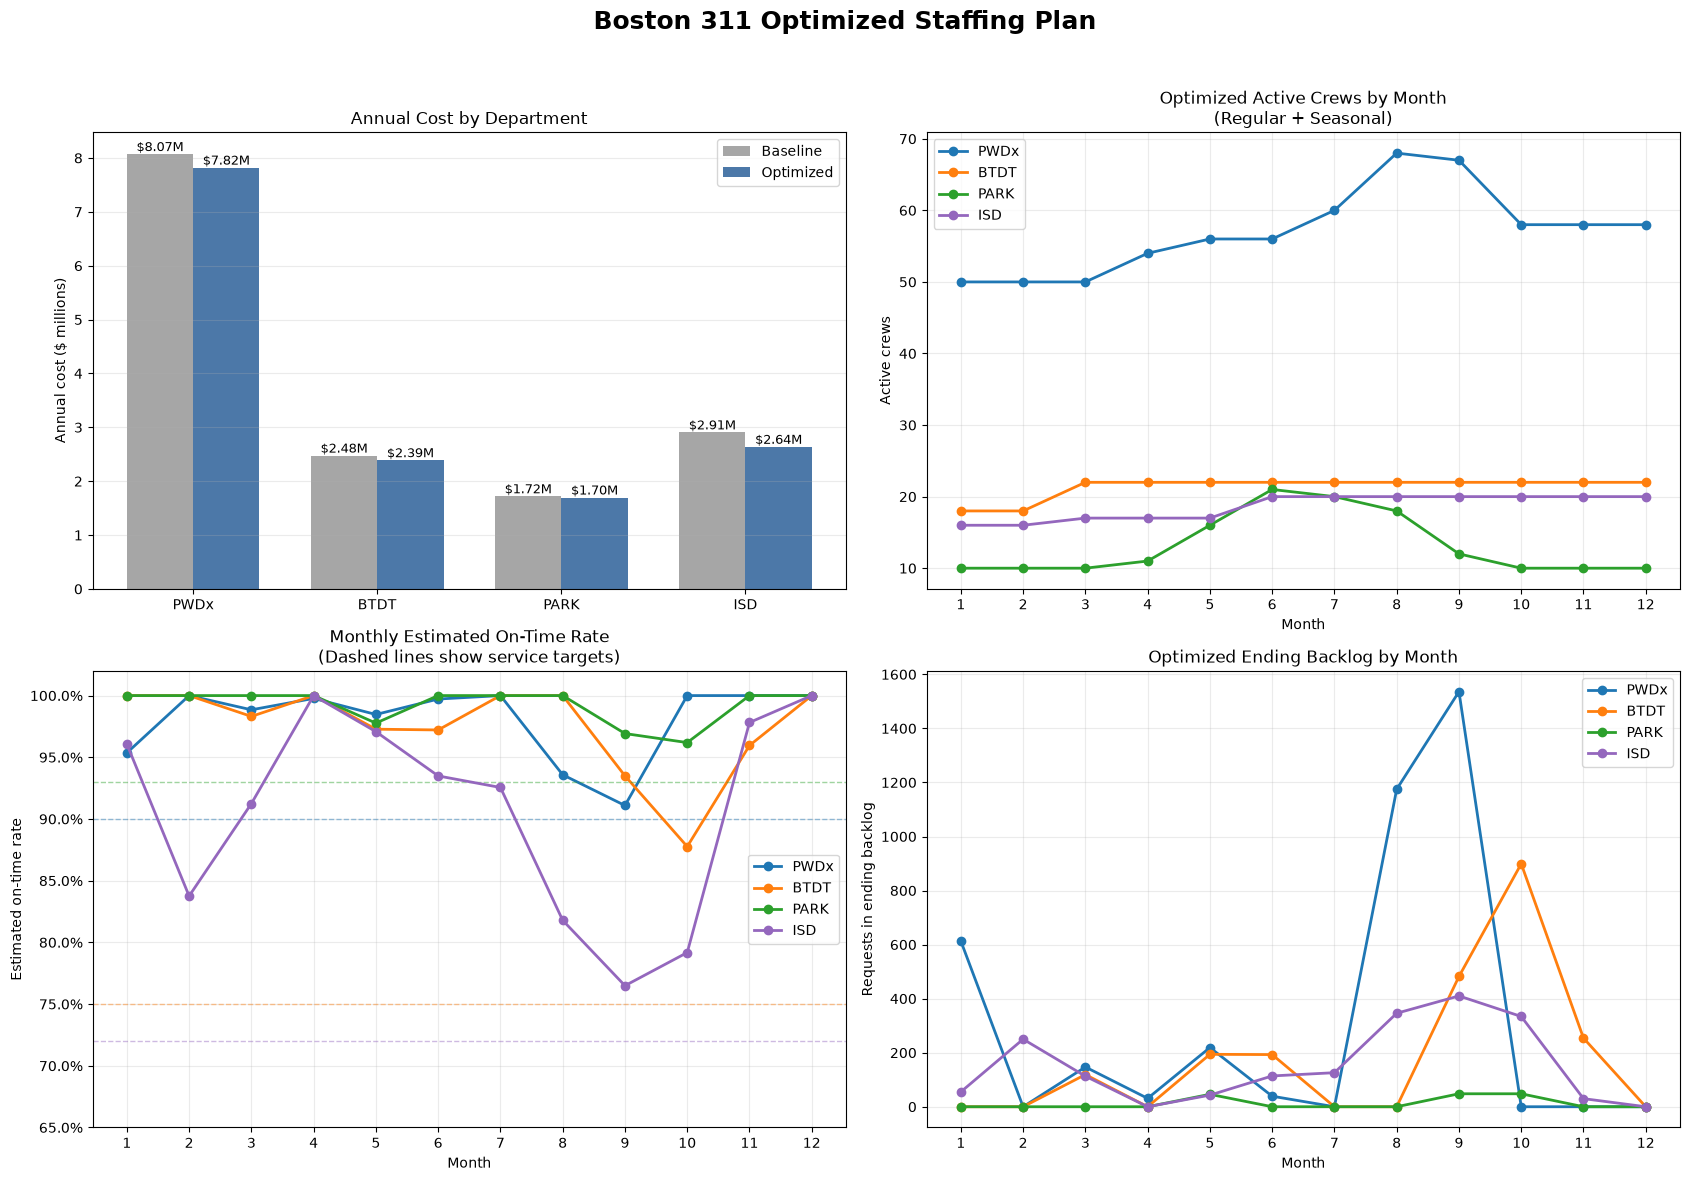

Dashboard saved to: /Users/mihir/Desktop/Hackathon/data/output/staffing_optimization_dashboard.png


In [41]:
# PART 3 — STEP 3.13
# Visualize optimized staffing, service, backlog, and cost

from matplotlib.ticker import PercentFormatter

chart_order = ["PWDx", "BTDT", "PARK", "ISD"]

department_colors = {
    "PWDx": "#1f77b4",
    "BTDT": "#ff7f0e",
    "PARK": "#2ca02c",
    "ISD": "#9467bd"
}


# Prepare chart data
chart_plan = optimized_staffing_plan.copy()

chart_plan["month_number"] = (
    chart_plan["month"].dt.month
)

chart_plan["active_crews"] = (
    chart_plan["regular_crews"]
    + chart_plan["seasonal_crews"]
)


cost_chart_data = (
    annual_plan_comparison
    .set_index("department")
    .reindex(chart_order)
    .reset_index()
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12)
)

fig.suptitle(
    "Boston 311 Optimized Staffing Plan",
    fontsize=18,
    fontweight="bold"
)


# Chart 1: Baseline versus optimized annual cost
ax = axes[0, 0]

x_positions = np.arange(len(chart_order))
bar_width = 0.36

baseline_bars = ax.bar(
    x_positions - bar_width / 2,
    cost_chart_data["baseline_annual_cost"] / 1_000_000,
    width=bar_width,
    label="Baseline",
    color="#a6a6a6"
)

optimized_bars = ax.bar(
    x_positions + bar_width / 2,
    cost_chart_data["optimized_annual_cost"] / 1_000_000,
    width=bar_width,
    label="Optimized",
    color="#4c78a8"
)

ax.set_title("Annual Cost by Department")
ax.set_ylabel("Annual cost ($ millions)")
ax.set_xticks(x_positions)
ax.set_xticklabels(chart_order)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [baseline_bars, optimized_bars]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"${height:.2f}M",
            ha="center",
            va="bottom",
            fontsize=9
        )


# Chart 2: Optimized active crews by month
ax = axes[0, 1]

for department in chart_order:

    department_plan = chart_plan[
        chart_plan["department"] == department
    ].sort_values("month_number")

    ax.plot(
        department_plan["month_number"],
        department_plan["active_crews"],
        marker="o",
        linewidth=2,
        label=department,
        color=department_colors[department]
    )

ax.set_title(
    "Optimized Active Crews by Month\n"
    "(Regular + Seasonal)"
)
ax.set_xlabel("Month")
ax.set_ylabel("Active crews")
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(alpha=0.25)


# Chart 3: Monthly service performance
ax = axes[1, 0]

for department in chart_order:

    department_plan = chart_plan[
        chart_plan["department"] == department
    ].sort_values("month_number")

    ax.plot(
        department_plan["month_number"],
        department_plan["estimated_on_time_rate"],
        marker="o",
        linewidth=2,
        label=department,
        color=department_colors[department]
    )

    ax.axhline(
        SERVICE_LEVEL_TARGETS[department],
        linestyle="--",
        linewidth=1,
        alpha=0.45,
        color=department_colors[department]
    )

ax.set_title(
    "Monthly Estimated On-Time Rate\n"
    "(Dashed lines show service targets)"
)
ax.set_xlabel("Month")
ax.set_ylabel("Estimated on-time rate")
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
ax.set_ylim(0.65, 1.02)
ax.legend()
ax.grid(alpha=0.25)


# Chart 4: Monthly ending backlog
ax = axes[1, 1]

for department in chart_order:

    department_plan = chart_plan[
        chart_plan["department"] == department
    ].sort_values("month_number")

    ax.plot(
        department_plan["month_number"],
        department_plan["ending_backlog"],
        marker="o",
        linewidth=2,
        label=department,
        color=department_colors[department]
    )

ax.set_title("Optimized Ending Backlog by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Requests in ending backlog")
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(alpha=0.25)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


dashboard_path = (
    OUTPUT_DIR
    / "staffing_optimization_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Dashboard saved to: {dashboard_path}"
)

### Optimized Staffing Dashboard

The dashboard summarizes the cost, staffing, service, and backlog implications of the optimized plan.

The annual-cost comparison shows that optimization reduces costs for every department. Public Works produces the largest dollar savings, while Inspectional Services achieves the largest percentage reduction.

Monthly staffing follows the forecasted demand pattern. Public Works increases from 50 crews at the beginning of the year to a peak of 68 crews during the August demand peak, before falling to 58 crews later in the year. Transportation reaches 22 crews, while Inspectional Services reaches 20. Parks combines its 10 regular crews with seasonal crews during the April-to-October operating window.

The estimated monthly on-time rates remain above the required service targets:

- Public Works: 90%
- Transportation: 75%
- Parks and Recreation: 93%
- Inspectional Services: 72%

The optimizer allows temporary backlog when immediately adding permanent crews would be more expensive. Public Works experiences its largest backlog during the August–September demand peak, while Transportation and Inspectional Services carry smaller temporary backlogs. Parks experiences only limited backlog.

All departments finish December with zero backlog, confirming that the model does not defer unresolved 2025 requests into 2026.

In [46]:
# PART 3 — STEP 3.14
# Validate and export the final optimization results

# ---------------------------------------------------------
# 1. Validate the final table structure
# ---------------------------------------------------------

expected_departments = {
    "PWDx",
    "BTDT",
    "PARK",
    "ISD"
}

assert len(optimized_staffing_plan) == 48

assert set(
    optimized_staffing_plan["department"]
) == expected_departments

assert (
    optimized_staffing_plan[
        ["department", "month"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert (
    optimized_staffing_plan[
        "forecast_requests"
    ]
    .notna()
    .all()
)


# ---------------------------------------------------------
# 2. Validate crew decisions
# ---------------------------------------------------------

crew_columns = [
    "regular_crews",
    "crews_hired",
    "crews_released",
    "seasonal_crews"
]

for column in crew_columns:

    assert (
        optimized_staffing_plan[column] >= 0
    ).all()

    assert np.allclose(
        optimized_staffing_plan[column],
        np.round(
            optimized_staffing_plan[column]
        )
    )


# ---------------------------------------------------------
# 3. Validate backlog and cost values
# ---------------------------------------------------------

for column in [
    "ending_backlog",
    "backlog_over_30_days",
    "total_monthly_cost"
]:

    assert (
        optimized_staffing_plan[column] >= 0
    ).all()

    assert (
        optimized_staffing_plan[column]
        .notna()
        .all()
    )


# ---------------------------------------------------------
# 4. Validate Parks seasonal-crew restrictions
# ---------------------------------------------------------

invalid_seasonal_rows = (
    (optimized_staffing_plan["seasonal_crews"] > 0)
    & (
        (optimized_staffing_plan["department"] != "PARK")
        | (
            ~optimized_staffing_plan[
                "month"
            ].dt.month.between(4, 10)
        )
    )
)

assert not invalid_seasonal_rows.any()


# ---------------------------------------------------------
# 5. Validate January starting crews
# ---------------------------------------------------------

starting_crew_lookup = (
    staffing_assumptions
    .set_index("department")[
        "starting_crews"
    ]
    .to_dict()
)

for department in department_order:

    department_plan = (
        optimized_staffing_plan[
            optimized_staffing_plan[
                "department"
            ] == department
        ]
        .sort_values("month")
        .reset_index(drop=True)
    )

    assert (
        department_plan.loc[
            0,
            "regular_crews"
        ]
        == starting_crew_lookup[department]
    )


# ---------------------------------------------------------
# 6. Validate one-month workforce transitions
# ---------------------------------------------------------

for department in department_order:

    department_plan = (
        optimized_staffing_plan[
            optimized_staffing_plan[
                "department"
            ] == department
        ]
        .sort_values("month")
        .reset_index(drop=True)
    )

    for month_index in range(1, 12):

        expected_regular_crews = (
            department_plan.loc[
                month_index - 1,
                "regular_crews"
            ]
            + department_plan.loc[
                month_index - 1,
                "crews_hired"
            ]
            - department_plan.loc[
                month_index - 1,
                "crews_released"
            ]
        )

        actual_regular_crews = (
            department_plan.loc[
                month_index,
                "regular_crews"
            ]
        )

        assert (
            actual_regular_crews
            == expected_regular_crews
        )


# ---------------------------------------------------------
# 7. Validate monthly service targets
# ---------------------------------------------------------

for department in department_order:

    department_plan = (
        optimized_staffing_plan[
            optimized_staffing_plan[
                "department"
            ] == department
        ]
    )

    assert (
        department_plan[
            "estimated_on_time_rate"
        ]
        + 1e-9
        >= SERVICE_LEVEL_TARGETS[department]
    ).all()


# ---------------------------------------------------------
# 8. Validate December backlog
# ---------------------------------------------------------

for department in department_order:

    department_plan = (
        optimized_staffing_plan[
            optimized_staffing_plan[
                "department"
            ] == department
        ]
        .sort_values("month")
        .reset_index(drop=True)
    )

    december_backlog = (
        department_plan.loc[
            11,
            "ending_backlog"
        ]
    )

    assert december_backlog == 0


# ---------------------------------------------------------
# 9. Validate total optimized cost
# ---------------------------------------------------------

final_optimized_cost = (
    optimized_staffing_plan[
        "total_monthly_cost"
    ].sum()
)

expected_optimized_cost = 14_545_446.666666666

assert np.isclose(
    final_optimized_cost,
    expected_optimized_cost,
    atol=1
)


# ---------------------------------------------------------
# 10. Prepare clean export tables
# ---------------------------------------------------------

optimized_plan_export = (
    optimized_staffing_plan.copy()
)

optimized_plan_export["month"] = (
    optimized_plan_export["month"]
    .dt.strftime("%Y-%m")
)

optimized_summary_export = (
    optimized_annual_summary
    .reset_index()
)

comparison_export = (
    annual_plan_comparison.copy()
)


# ---------------------------------------------------------
# 11. Define output file paths
# ---------------------------------------------------------

optimized_plan_path = (
    OUTPUT_DIR
    / "boston_311_optimized_staffing_plan.csv"
)

optimized_summary_path = (
    OUTPUT_DIR
    / "boston_311_optimized_annual_summary.csv"
)

comparison_path = (
    OUTPUT_DIR
    / "boston_311_baseline_vs_optimized.csv"
)


# ---------------------------------------------------------
# 12. Export final deliverables
# ---------------------------------------------------------

optimized_plan_export.to_csv(
    optimized_plan_path,
    index=False
)

optimized_summary_export.to_csv(
    optimized_summary_path,
    index=False
)

comparison_export.to_csv(
    comparison_path,
    index=False
)


# ---------------------------------------------------------
# 13. Confirm completion
# ---------------------------------------------------------

print("Final optimization validation passed!")

print(
    f"Optimized monthly plan saved to:\n"
    f"{optimized_plan_path}"
)

print(
    f"\nOptimized annual summary saved to:\n"
    f"{optimized_summary_path}"
)

print(
    f"\nBaseline comparison saved to:\n"
    f"{comparison_path}"
)

print(
    "\nFinal optimized annual cost:",
    f"${final_optimized_cost:,.0f}"
)

Final optimization validation passed!
Optimized monthly plan saved to:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_optimized_staffing_plan.csv

Optimized annual summary saved to:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_optimized_annual_summary.csv

Baseline comparison saved to:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_baseline_vs_optimized.csv

Final optimized annual cost: $14,545,447


### Final Optimization Validation and Exports

The final optimized staffing plan passed all structural, workforce, service, and cost validations.

The validation confirms that:

- The plan contains exactly 48 department-month records.
- Every department begins January with the crew level specified in the Boston 311 brief.
- All crew decisions are nonnegative whole numbers.
- Hiring and release decisions follow the required one-month delay.
- Seasonal crews are used only by Parks and Recreation from April through October.
- Every department satisfies its monthly service-level target.
- Every department finishes December with zero backlog.
- The final optimized annual cost equals **$14,545,447**.

Three final data files were exported:

1. `boston_311_optimized_staffing_plan.csv` — monthly staffing, capacity, backlog, service, and cost results.
2. `boston_311_optimized_annual_summary.csv` — annual optimized results by department.
3. `boston_311_baseline_vs_optimized.csv` — comparison of baseline and optimized staffing plans.



In [48]:
# PART 4 — STEP 4.1
# Prepare baseline, low-demand, and high-demand inputs

DEMAND_SCENARIO_MULTIPLIERS = {
    "Low (-20%)": 0.80,
    "Baseline": 1.00,
    "High (+20%)": 1.20
}

scenario_input_tables = []

for scenario, multiplier in (
    DEMAND_SCENARIO_MULTIPLIERS.items()
):

    scenario_data = staffing_inputs.copy()

    scenario_data["scenario"] = scenario

    scenario_data["forecast_requests"] = np.floor(
        scenario_data["forecast_requests"]
        * multiplier
        + 0.5
    ).astype(int)

    # Recalculate capacity-only measures using
    # the scenario-adjusted demand
    scenario_data[
        "required_crews_capacity_only"
    ] = np.ceil(
        scenario_data["forecast_requests"]
        / scenario_data[
            "monthly_capacity_per_crew"
        ]
    ).astype(int)

    scenario_data[
        "crew_gap_vs_jan_start"
    ] = (
        scenario_data[
            "required_crews_capacity_only"
        ]
        - scenario_data["starting_crews"]
    )

    scenario_data[
        "backlog_if_starting_crews_held"
    ] = np.maximum(
        scenario_data["forecast_requests"]
        - scenario_data["starting_capacity"],
        0
    )

    scenario_input_tables.append(
        scenario_data
    )


sensitivity_staffing_inputs = (
    pd.concat(
        scenario_input_tables,
        ignore_index=True
    )
    .sort_values(
        ["scenario", "department", "month"]
    )
    .reset_index(drop=True)
)


# Validate each scenario
for scenario in (
    DEMAND_SCENARIO_MULTIPLIERS
):

    scenario_data = (
        sensitivity_staffing_inputs[
            sensitivity_staffing_inputs[
                "scenario"
            ] == scenario
        ]
    )

    assert len(scenario_data) == 48

    assert (
        scenario_data[
            ["department", "month"]
        ]
        .duplicated()
        .sum()
        == 0
    )

    assert (
        scenario_data[
            "forecast_requests"
        ] >= 0
    ).all()


scenario_demand_summary = (
    sensitivity_staffing_inputs
    .groupby(
        ["scenario", "department"]
    )["forecast_requests"]
    .sum()
    .reset_index()
)


scenario_total_demand = (
    sensitivity_staffing_inputs
    .groupby("scenario")[
        "forecast_requests"
    ]
    .sum()
    .to_dict()
)


expected_scenario_totals = {
    "Low (-20%)": 223476,
    "Baseline": 279343,
    "High (+20%)": 335210
}

assert (
    scenario_total_demand
    == expected_scenario_totals
)


scenario_demand_table = (
    scenario_demand_summary
    .pivot(
        index="department",
        columns="scenario",
        values="forecast_requests"
    )
    .reindex(
        columns=[
            "Low (-20%)",
            "Baseline",
            "High (+20%)"
        ]
    )
)


display(scenario_demand_table)

print("\nTotal annual demand by scenario:")

for scenario in [
    "Low (-20%)",
    "Baseline",
    "High (+20%)"
]:
    print(
        f"{scenario}: "
        f"{scenario_total_demand[scenario]:,}"
    )

print(
    "\nDemand sensitivity inputs "
    "created successfully."
)

scenario,Low (-20%),Baseline,High (+20%)
department,,,
BTDT,62707,78383,94059
ISD,14701,18376,22051
PARK,14514,18143,21772
PWDx,131554,164441,197328



Total annual demand by scenario:
Low (-20%): 223,476
Baseline: 279,343
High (+20%): 335,210

Demand sensitivity inputs created successfully.


### Demand Sensitivity Scenarios

Three demand scenarios are prepared to evaluate how the staffing plan responds when actual 2025 service requests differ from the baseline forecast.

- **Low-demand scenario:** Demand is reduced by 20%, producing 223,476 annual requests.
- **Baseline scenario:** The original forecast contains 279,343 annual requests.
- **High-demand scenario:** Demand is increased by 20%, producing 335,210 annual requests.

The adjustment is applied separately to every department-month forecast, preserving the original seasonal demand pattern. Request counts are rounded to whole numbers.

These scenarios are planning assumptions rather than statistical confidence intervals. They are used to evaluate changes in staffing levels, backlog, service performance, and annual cost under lower- and higher-demand conditions.

In [51]:
# PART 4 — STEP 4.2
# Optimize all demand scenarios.


scenario_order = [
    "Low (-20%)",
    "Baseline",
    "High (+20%)"
]


def solve_sensitivity_model(
    department_data
):

    model = create_department_model_arrays(
        department_data
    )

    model = add_workforce_constraints(
        model
    )

    # Record where the service constraints begin
    service_constraint_start = len(
        model["constraint_rows"]
    )

    model = add_service_constraints(
        model
    )

    department_data = (
        model["department_data"]
    )

    department = model["department"]

    normal_target = (
        SERVICE_LEVEL_TARGETS[department]
    )

    january_forecast = int(
        department_data.loc[
            0,
            "forecast_requests"
        ]
    )

    january_starting_crews = int(
        department_data.loc[
            0,
            "starting_crews"
        ]
    )

    monthly_capacity_per_crew = int(
        department_data.loc[
            0,
            "monthly_capacity_per_crew"
        ]
    )

    january_capacity = (
        january_starting_crews
        * monthly_capacity_per_crew
    )

    maximum_january_rate = min(
        january_capacity
        / january_forecast,
        1.0
    )

    effective_january_target = min(
        normal_target,
        maximum_january_rate
    )

    january_target_adjusted = (
        effective_january_target
        + 1e-9
        < normal_target
    )

    if january_target_adjusted:

        # For each month, the service constraint is
        # the second constraint added:
        # backlog, service, aged backlog.
        january_service_row = (
            service_constraint_start + 1
        )

        model["constraint_lower"][
            january_service_row
        ] = (
            effective_january_target
            * january_forecast
        )

    constraints = LinearConstraint(
        np.array(
            model["constraint_rows"]
        ),
        np.array(
            model["constraint_lower"]
        ),
        np.array(
            model["constraint_upper"]
        )
    )

    result = milp(
        c=model["objective"],
        integrality=model["integrality"],
        bounds=Bounds(
            model["lower_bounds"],
            model["upper_bounds"]
        ),
        constraints=constraints,
        options={
            "time_limit": 60
        }
    )

    return (
        result,
        model,
        effective_january_target,
        january_target_adjusted
    )


sensitivity_optimized_plans = []
sensitivity_summary_rows = []


for scenario in scenario_order:

    for department in department_order:

        department_data = (
            sensitivity_staffing_inputs[
                (
                    sensitivity_staffing_inputs[
                        "scenario"
                    ] == scenario
                )
                & (
                    sensitivity_staffing_inputs[
                        "department"
                    ] == department
                )
            ]
            .sort_values("month")
            .reset_index(drop=True)
            .copy()
        )

        (
            optimization_result,
            optimization_model,
            effective_january_target,
            january_target_adjusted
        ) = solve_sensitivity_model(
            department_data
        )

        if not optimization_result.success:
            raise RuntimeError(
                f"Optimization failed for "
                f"{scenario}, {department}: "
                f"{optimization_result.message}"
            )

        optimized_decisions = (
            extract_optimized_decisions(
                optimization_result,
                optimization_model
            )
        )

        # The existing result function checks one target
        # for every month. Temporarily use the feasible
        # January target, then restore the normal target.
        normal_target = (
            SERVICE_LEVEL_TARGETS[department]
        )

        try:

            SERVICE_LEVEL_TARGETS[
                department
            ] = effective_january_target

            optimized_plan = (
                calculate_optimized_results(
                    optimized_decisions,
                    department_data
                )
            )

        finally:

            SERVICE_LEVEL_TARGETS[
                department
            ] = normal_target

        optimized_plan["scenario"] = scenario

        optimized_plan[
            "service_target_applied"
        ] = normal_target

        optimized_plan[
            "january_target_adjusted"
        ] = False

        january_row = (
            optimized_plan["month"]
            == optimized_plan["month"].min()
        )

        optimized_plan.loc[
            january_row,
            "service_target_applied"
        ] = effective_january_target

        optimized_plan.loc[
            january_row,
            "january_target_adjusted"
        ] = january_target_adjusted

        # Validate the monthly targets actually applied
        assert (
            optimized_plan[
                "estimated_on_time_rate"
            ]
            + 1e-9
            >= optimized_plan[
                "service_target_applied"
            ]
        ).all()

        sensitivity_optimized_plans.append(
            optimized_plan
        )

        sensitivity_summary_rows.append({
            "scenario": scenario,
            "department": department,
            "optimization_successful":
                optimization_result.success,
            "annual_demand": int(
                optimized_plan[
                    "forecast_requests"
                ].sum()
            ),
            "peak_regular_crews": int(
                optimized_plan[
                    "regular_crews"
                ].max()
            ),
            "regular_crews_hired": int(
                optimized_plan[
                    "crews_hired"
                ].sum()
            ),
            "regular_crews_released": int(
                optimized_plan[
                    "crews_released"
                ].sum()
            ),
            "seasonal_crew_months": int(
                optimized_plan[
                    "seasonal_crews"
                ].sum()
            ),
            "minimum_on_time_rate": float(
                optimized_plan[
                    "estimated_on_time_rate"
                ].min()
            ),
            "normal_service_target":
                normal_target,
            "effective_january_target":
                effective_january_target,
            "january_target_adjusted":
                january_target_adjusted,
            "year_end_backlog": int(
                optimized_plan
                .sort_values("month")
                .iloc[-1][
                    "ending_backlog"
                ]
            ),
            "annual_cost": float(
                optimized_plan[
                    "total_monthly_cost"
                ].sum()
            )
        })


sensitivity_optimized_plan = (
    pd.concat(
        sensitivity_optimized_plans,
        ignore_index=True
    )
)

sensitivity_optimization_summary = (
    pd.DataFrame(
        sensitivity_summary_rows
    )
)


# Validate all scenario results
assert len(
    sensitivity_optimized_plan
) == 144

assert len(
    sensitivity_optimization_summary
) == 12

assert (
    sensitivity_optimization_summary[
        "optimization_successful"
    ]
).all()

assert (
    sensitivity_optimization_summary[
        "year_end_backlog"
    ]
    == 0
).all()

assert (
    sensitivity_optimized_plan[
        ["scenario", "department", "month"]
    ]
    .duplicated()
    .sum()
    == 0
)


# Confirm the sensitivity baseline matches
# the previously optimized baseline
sensitivity_baseline_cost = (
    sensitivity_optimization_summary[
        sensitivity_optimization_summary[
            "scenario"
        ] == "Baseline"
    ]["annual_cost"].sum()
)

assert np.isclose(
    sensitivity_baseline_cost,
    final_optimized_cost,
    atol=1
)


scenario_cost_summary = (
    sensitivity_optimization_summary
    .groupby("scenario")
    .agg(
        annual_demand=(
            "annual_demand",
            "sum"
        ),
        annual_cost=(
            "annual_cost",
            "sum"
        ),
        total_regular_hires=(
            "regular_crews_hired",
            "sum"
        ),
        total_regular_releases=(
            "regular_crews_released",
            "sum"
        ),
        seasonal_crew_months=(
            "seasonal_crew_months",
            "sum"
        ),
        minimum_on_time_rate=(
            "minimum_on_time_rate",
            "min"
        ),
        year_end_backlog=(
            "year_end_backlog",
            "sum"
        )
    )
    .reindex(scenario_order)
    .reset_index()
)


scenario_display = (
    scenario_cost_summary.copy()
)

scenario_display[
    "annual_demand"
] = (
    scenario_display[
        "annual_demand"
    ].map("{:,}".format)
)

scenario_display[
    "annual_cost"
] = (
    scenario_display[
        "annual_cost"
    ].map("${:,.0f}".format)
)

scenario_display[
    "minimum_on_time_rate"
] = (
    scenario_display[
        "minimum_on_time_rate"
    ].map("{:.2%}".format)
)


display(scenario_display)


january_exceptions = (
    sensitivity_optimization_summary[
        sensitivity_optimization_summary[
            "january_target_adjusted"
        ]
    ][
        [
            "scenario",
            "department",
            "normal_service_target",
            "effective_january_target"
        ]
    ]
)

print("\nJanuary feasibility exceptions:")

display(january_exceptions)


for _, row in (
    scenario_cost_summary.iterrows()
):
    print(
        f"{row['scenario']}: "
        f"${row['annual_cost']:,.0f}"
    )

print(
    "\nAll 12 sensitivity models "
    "solved successfully."
)

,scenario,annual_demand,annual_cost,total_regular_hires,total_regular_releases,seasonal_crew_months,minimum_on_time_rate,year_end_backlog
0,Low (-20%),"223,476","$12,297,287",11,18,30,72.83%,0
1,Baseline,"279,343","$14,545,447",26,10,38,76.49%,0
2,High (+20%),"335,210","$17,394,933",49,13,45,72.62%,0



January feasibility exceptions:


,scenario,department,normal_service_target,effective_january_target
8,High (+20%),PWDx,0.9,0.794652


Low (-20%): $12,297,287
Baseline: $14,545,447
High (+20%): $17,394,933

All 12 sensitivity models solved successfully.


### Optimized Demand Sensitivity Results

The staffing optimization model was evaluated under low-demand, baseline, and high-demand scenarios. All 12 department-scenario models solved successfully.

Under the **low-demand scenario**, annual demand decreases to 223,476 requests and optimized cost falls to **$12,297,287**. This is approximately **$2.25 million**, or **15.46%**, below the baseline optimized cost. The model requires 11 regular hires, 18 releases, and 30 Parks seasonal crew-months.

Under the **baseline scenario**, annual demand is 279,343 requests and optimized annual cost is **$14,545,447**. The model requires 26 regular hires, 10 releases, and 38 seasonal crew-months.

Under the **high-demand scenario**, annual demand increases to 335,210 requests and optimized cost rises to **$17,394,933**. This is approximately **$2.85 million**, or **19.59%**, above the baseline. The model requires 49 regular hires, 13 releases, and 45 seasonal crew-months.

The strict high-demand model initially identified an infeasible January service requirement for Public Works. With 50 fixed starting crews, January capacity is 12,600 requests, compared with 15,856 forecasted requests. The maximum achievable January on-time rate is therefore approximately **79.47%**, below the normal 90% target.

A transparent January-only feasibility exception is applied for this scenario. The normal Public Works service target remains in effect from February through December, all other department-month targets remain unchanged, and every scenario finishes December with zero backlog.

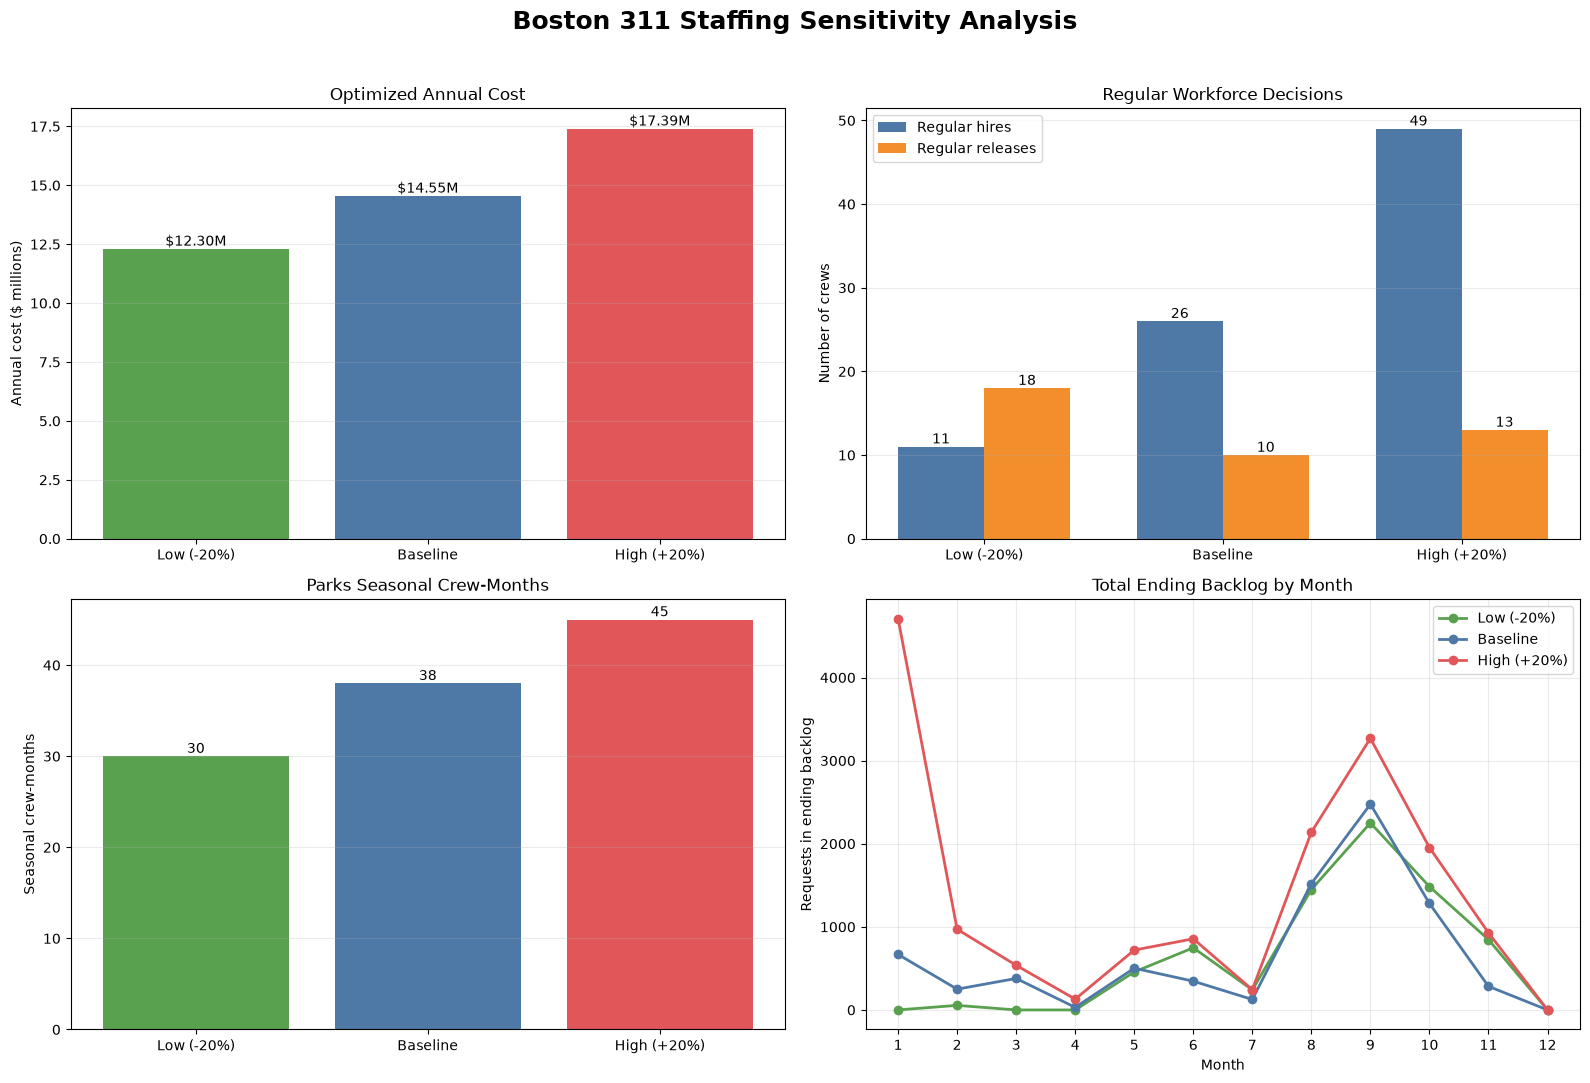

Sensitivity analysis exports completed!
Dashboard:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_sensitivity_dashboard.png

Monthly sensitivity plan:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_sensitivity_staffing_plan.csv

Department summary:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_sensitivity_department_summary.csv

Scenario summary:
/Users/mihir/Desktop/Hackathon/data/output/boston_311_sensitivity_scenario_summary.csv


In [52]:
# PART 4 — STEP 4.3
# Visualize and export demand sensitivity results

scenario_colors = {
    "Low (-20%)": "#59a14f",
    "Baseline": "#4e79a7",
    "High (+20%)": "#e15759"
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

fig.suptitle(
    "Boston 311 Staffing Sensitivity Analysis",
    fontsize=18,
    fontweight="bold"
)


# ---------------------------------------------------------
# Chart 1: Annual optimized cost
# ---------------------------------------------------------

ax = axes[0, 0]

cost_values = (
    scenario_cost_summary[
        "annual_cost"
    ] / 1_000_000
)

cost_bars = ax.bar(
    scenario_cost_summary["scenario"],
    cost_values,
    color=[
        scenario_colors[scenario]
        for scenario in scenario_order
    ]
)

ax.set_title("Optimized Annual Cost")
ax.set_ylabel("Annual cost ($ millions)")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(
    cost_bars,
    cost_values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"${value:.2f}M",
        ha="center",
        va="bottom",
        fontsize=10
    )


# ---------------------------------------------------------
# Chart 2: Regular hires and releases
# ---------------------------------------------------------

ax = axes[0, 1]

x_positions = np.arange(
    len(scenario_order)
)

bar_width = 0.36

hire_bars = ax.bar(
    x_positions - bar_width / 2,
    scenario_cost_summary[
        "total_regular_hires"
    ],
    width=bar_width,
    label="Regular hires",
    color="#4e79a7"
)

release_bars = ax.bar(
    x_positions + bar_width / 2,
    scenario_cost_summary[
        "total_regular_releases"
    ],
    width=bar_width,
    label="Regular releases",
    color="#f28e2b"
)

ax.set_title("Regular Workforce Decisions")
ax.set_ylabel("Number of crews")
ax.set_xticks(x_positions)
ax.set_xticklabels(scenario_order)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [
    hire_bars,
    release_bars
]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(bar.get_height())}",
            ha="center",
            va="bottom",
            fontsize=10
        )


# ---------------------------------------------------------
# Chart 3: Parks seasonal crew-months
# ---------------------------------------------------------

ax = axes[1, 0]

seasonal_bars = ax.bar(
    scenario_cost_summary["scenario"],
    scenario_cost_summary[
        "seasonal_crew_months"
    ],
    color=[
        scenario_colors[scenario]
        for scenario in scenario_order
    ]
)

ax.set_title(
    "Parks Seasonal Crew-Months"
)
ax.set_ylabel("Seasonal crew-months")
ax.grid(axis="y", alpha=0.25)

for bar in seasonal_bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom",
        fontsize=10
    )


# ---------------------------------------------------------
# Chart 4: Total monthly ending backlog
# ---------------------------------------------------------

ax = axes[1, 1]

monthly_scenario_backlog = (
    sensitivity_optimized_plan
    .groupby(
        ["scenario", "month"]
    )["ending_backlog"]
    .sum()
    .reset_index()
)

for scenario in scenario_order:

    scenario_backlog = (
        monthly_scenario_backlog[
            monthly_scenario_backlog[
                "scenario"
            ] == scenario
        ]
        .sort_values("month")
    )

    ax.plot(
        scenario_backlog[
            "month"
        ].dt.month,
        scenario_backlog[
            "ending_backlog"
        ],
        marker="o",
        linewidth=2,
        label=scenario,
        color=scenario_colors[scenario]
    )

ax.set_title(
    "Total Ending Backlog by Month"
)
ax.set_xlabel("Month")
ax.set_ylabel("Requests in ending backlog")
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(alpha=0.25)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


sensitivity_dashboard_path = (
    OUTPUT_DIR
    / "boston_311_sensitivity_dashboard.png"
)

fig.savefig(
    sensitivity_dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# Prepare and export sensitivity tables
# ---------------------------------------------------------

sensitivity_plan_export = (
    sensitivity_optimized_plan.copy()
)

sensitivity_plan_export["month"] = (
    sensitivity_plan_export["month"]
    .dt.strftime("%Y-%m")
)


sensitivity_plan_path = (
    OUTPUT_DIR
    / "boston_311_sensitivity_staffing_plan.csv"
)

sensitivity_department_summary_path = (
    OUTPUT_DIR
    / "boston_311_sensitivity_department_summary.csv"
)

sensitivity_scenario_summary_path = (
    OUTPUT_DIR
    / "boston_311_sensitivity_scenario_summary.csv"
)


sensitivity_plan_export.to_csv(
    sensitivity_plan_path,
    index=False
)

sensitivity_optimization_summary.to_csv(
    sensitivity_department_summary_path,
    index=False
)

scenario_cost_summary.to_csv(
    sensitivity_scenario_summary_path,
    index=False
)


print("Sensitivity analysis exports completed!")

print(
    f"Dashboard:\n"
    f"{sensitivity_dashboard_path}"
)

print(
    f"\nMonthly sensitivity plan:\n"
    f"{sensitivity_plan_path}"
)

print(
    f"\nDepartment summary:\n"
    f"{sensitivity_department_summary_path}"
)

print(
    f"\nScenario summary:\n"
    f"{sensitivity_scenario_summary_path}"
)

### Demand Sensitivity Dashboard and Conclusions

The sensitivity dashboard shows how staffing decisions, backlog, and annual cost change under alternative demand conditions.

Optimized annual cost ranges from **$12.30 million** under the low-demand scenario to **$17.39 million** under the high-demand scenario. The baseline optimized cost is **$14.55 million**.

Regular workforce decisions respond strongly to demand:

- Low demand requires 11 hires and 18 releases.
- Baseline demand requires 26 hires and 10 releases.
- High demand requires 49 hires and 13 releases.

Parks seasonal staffing also changes with demand. Seasonal use increases from 30 crew-months under low demand to 38 under baseline demand and 45 under high demand.

The high-demand scenario creates the largest temporary backlog, particularly in January and during the late-summer demand peak. The January spike reflects the one-month hiring delay and the fixed January starting workforce. Additional crews cannot become available immediately after higher demand is observed.

Lower demand does not eliminate backlog entirely because the cost-minimizing model may carry requests temporarily when adding or retaining another crew would cost more than the resulting backlog penalty. Nevertheless, all scenarios clear their backlogs by December.

The sensitivity analysis demonstrates that the optimized plan is responsive to changing demand but remains vulnerable to unexpected demand increases at the beginning of the planning horizon. Advance hiring decisions, contingency crews, overtime capacity, or an emergency-response reserve could reduce this risk.

# Final Conclusions and Recommendations

## Executive Summary

This analysis combines the 2025 Boston 311 demand forecast with a mixed-integer staffing optimization model for Public Works, Transportation, Parks and Recreation, and Inspectional Services.

The final forecast contains **279,343 service requests**:

- Public Works: 164,441
- Transportation: 78,383
- Parks and Recreation: 18,143
- Inspectional Services: 18,376

The capacity-focused baseline staffing plan costs **$15,173,360**. The optimized plan costs **$14,545,447**, producing estimated annual savings of **$627,913**, or **4.14%**.

The optimized plan satisfies the monthly planning targets for all four departments and clears all remaining backlog by December.

## Department-Level Findings

### Public Works

Public Works accounts for the largest share of demand and staffing cost. The optimized plan reduces peak regular staffing from 73 to 68 crews and releases 10 crews when demand declines. This produces estimated savings of **$251,227**.

### Transportation

Transportation requires fewer hires under the optimized plan. Peak staffing falls from 24 to 22 crews, producing estimated savings of **$85,513** while exceeding the 75% monthly service target.

### Parks and Recreation

Parks uses seasonal crews during the permitted April-to-October period. The optimized plan uses 38 seasonal crew-months instead of 40, producing savings of **$23,160** while maintaining the 93% service target.

### Inspectional Services

Inspectional Services produces the largest percentage reduction. The optimized plan hires four crews instead of seven, generating estimated savings of **$268,013**, or **9.22%**.

## Sensitivity Analysis

The optimized annual cost changes substantially when demand varies:

| Scenario | Annual demand | Optimized cost |
|---|---:|---:|
| Low demand (−20%) | 223,476 | $12,297,287 |
| Baseline | 279,343 | $14,545,447 |
| High demand (+20%) | 335,210 | $17,394,933 |

The high-demand scenario requires 49 regular hires and 45 Parks seasonal crew-months. It also creates a significant January backlog because the starting workforce is fixed and new crews require one month of hiring and training.

Under high demand, Public Works can complete only approximately 79.47% of January requests on time with its 50 starting crews. This is below its normal 90% target. A transparent January-only feasibility exception is therefore reported; the normal target remains in effect from February through December.

## Implementation Recommendations

1. **Begin peak-season hiring in advance.** Public Works demand peaks during August, so hiring decisions should begin early enough to account for the one-month training delay.

2. **Continue using seasonal Parks crews.** Seasonal staffing provides flexibility during April through October without permanently increasing the winter workforce.

3. **Monitor forecasts monthly.** Actual demand should be compared with the baseline, low, and high scenarios so hiring decisions can be adjusted before shortages develop.

4. **Create contingency capacity.** Overtime, temporary crews, cross-department support, or an emergency reserve should be considered for unexpected demand increases that occur before regular crews can be hired.

5. **Review release decisions carefully.** Crew releases reduce recurring staffing costs but require one month of notice and a charge equal to 25% of annual crew cost.

6. **Track service performance alongside cost.** Cost reductions should not be evaluated without confirming that department-level service targets and year-end backlog requirements remain satisfied.

## Limitations

The demand forecast is based on only two historical years, limiting the ability to distinguish long-term trends from temporary changes. The forecast does not explicitly model severe weather, policy changes, reporting behavior, employee absences, geographic travel time, or differences in request complexity.

Estimated on-time rates are capacity-based planning measures rather than predictions derived from individual request completion times. The optimization model also assumes that every crew within a department has the same productivity and monthly cost.

The low- and high-demand scenarios are planning assumptions rather than statistical confidence intervals. Actual future demand may differ from both scenarios.

## Exported Deliverables

The completed analysis produces the following files:

- `boston_311_2025_forecast.csv`
- `boston_311_demand_scenarios.csv`
- `boston_311_optimized_staffing_plan.csv`
- `boston_311_optimized_annual_summary.csv`
- `boston_311_baseline_vs_optimized.csv`
- `staffing_optimization_dashboard.png`
- `boston_311_sensitivity_staffing_plan.csv`
- `boston_311_sensitivity_department_summary.csv`
- `boston_311_sensitivity_scenario_summary.csv`
- `boston_311_sensitivity_dashboard.png`


# Final Conclusions and Recommendations

## Executive Summary

This analysis combines the 2025 Boston 311 demand forecast with a mixed-integer staffing optimization model for Public Works, Transportation, Parks and Recreation, and Inspectional Services.

The final forecast contains **279,343 service requests**:

- Public Works: 164,441
- Transportation: 78,383
- Parks and Recreation: 18,143
- Inspectional Services: 18,376

The capacity-focused baseline staffing plan costs **$15,173,360**. The optimized plan costs **$14,545,447**, producing estimated annual savings of **$627,913**, or **4.14%**.

The optimized plan satisfies the monthly planning targets for all four departments and clears all remaining backlog by December.

## Department-Level Findings

### Public Works

Public Works accounts for the largest share of demand and staffing cost. The optimized plan reduces peak regular staffing from 73 to 68 crews and releases 10 crews when demand declines. This produces estimated savings of **$251,227**.

### Transportation

Transportation requires fewer hires under the optimized plan. Peak staffing falls from 24 to 22 crews, producing estimated savings of **$85,513** while exceeding the 75% monthly service target.

### Parks and Recreation

Parks uses seasonal crews during the permitted April-to-October period. The optimized plan uses 38 seasonal crew-months instead of 40, producing savings of **$23,160** while maintaining the 93% service target.

### Inspectional Services

Inspectional Services produces the largest percentage reduction. The optimized plan hires four crews instead of seven, generating estimated savings of **$268,013**, or **9.22%**.

## Sensitivity Analysis

The optimized annual cost changes substantially when demand varies:

| Scenario | Annual demand | Optimized cost |
|---|---:|---:|
| Low demand (−20%) | 223,476 | $12,297,287 |
| Baseline | 279,343 | $14,545,447 |
| High demand (+20%) | 335,210 | $17,394,933 |

The high-demand scenario requires 49 regular hires and 45 Parks seasonal crew-months. It also creates a significant January backlog because the starting workforce is fixed and new crews require one month of hiring and training.

Under high demand, Public Works can complete only approximately 79.47% of January requests on time with its 50 starting crews. This is below its normal 90% target. A transparent January-only feasibility exception is therefore reported; the normal target remains in effect from February through December.

## Implementation Recommendations

1. **Begin peak-season hiring in advance.** Public Works demand peaks during August, so hiring decisions should begin early enough to account for the one-month training delay.

2. **Continue using seasonal Parks crews.** Seasonal staffing provides flexibility during April through October without permanently increasing the winter workforce.

3. **Monitor forecasts monthly.** Actual demand should be compared with the baseline, low, and high scenarios so hiring decisions can be adjusted before shortages develop.

4. **Create contingency capacity.** Overtime, temporary crews, cross-department support, or an emergency reserve should be considered for unexpected demand increases that occur before regular crews can be hired.

5. **Review release decisions carefully.** Crew releases reduce recurring staffing costs but require one month of notice and a charge equal to 25% of annual crew cost.

6. **Track service performance alongside cost.** Cost reductions should not be evaluated without confirming that department-level service targets and year-end backlog requirements remain satisfied.

## Limitations

The demand forecast is based on only two historical years, limiting the ability to distinguish long-term trends from temporary changes. The forecast does not explicitly model severe weather, policy changes, reporting behavior, employee absences, geographic travel time, or differences in request complexity.

Estimated on-time rates are capacity-based planning measures rather than predictions derived from individual request completion times. The optimization model also assumes that every crew within a department has the same productivity and monthly cost.

The low- and high-demand scenarios are planning assumptions rather than statistical confidence intervals. Actual future demand may differ from both scenarios.

## Exported Deliverables

The completed analysis produces the following files:

- `boston_311_2025_forecast.csv`
- `boston_311_demand_scenarios.csv`
- `boston_311_optimized_staffing_plan.csv`
- `boston_311_optimized_annual_summary.csv`
- `boston_311_baseline_vs_optimized.csv`
- `staffing_optimization_dashboard.png`
- `boston_311_sensitivity_staffing_plan.csv`
- `boston_311_sensitivity_department_summary.csv`
- `boston_311_sensitivity_scenario_summary.csv`
- `boston_311_sensitivity_dashboard.png`
